# Stage D: Cross-Sensor Identity Linking & Direction

See `docs/specs/2026-07-30-stage-d-direction-linking-design.md` for the
full design. This notebook: (1) reproduces the three ground-truth
findings that motivated the design, (2) calibrates the matcher against
`DATA/combined_file_manual.csv`, (3) applies it to all dual-sensor dates,
(4) writes the matched-pair output table, and (5) reports honestly on how
well direction detection actually works. All matching, scoring and
calibration logic is defined in this notebook -- self-contained, no
external Stage D module.

In [1]:
import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

DATA_DIR = "../DATA"

## Core matching & calibration functions

Three constants anchor the design:

- **`RSSI_TREND_SCALE = 0.5` dB/s.** The characteristic magnitude of a
  session's `rssi_trend`. Chosen from the real Stage-C session tables (see
  the empirical check further below): `|rssi_trend|` has median ~0.085,
  p75 ~0.21, p90 ~0.52, p95 ~1.0 dB/s on both sensors, so 0.5 sits around
  the 90th percentile -- a trend that steep is already a clear,
  unambiguous fade/rise, so the shape score *saturates* there instead of
  letting the handful of `|trend|` up to 16 dominate everything else.
- **`DEFAULT_MAX_TRANSIT_S = 300.0` s.** The upper bound of the transit
  gate's *fallback* default and outer search range. The sensors are ~20m
  apart with an expected ~20-30s walking transit; 300s implies a walking
  speed of 0.067 m/s -- an order of magnitude of slack over "someone
  dawdled". Originally treated as a fixed physical gate rather than a
  tuning knob; this revision instead sweeps it (see the calibration
  section below) after noticing no accepted match ever approached it and
  that a wide gate is a plausible source of the direction-skew problem.
- **`FORBIDDEN_EDGE_SCORE = -1e6`.** A large finite penalty (not `-inf`)
  used to forbid below-threshold edges in the bipartite assignment.
  `scipy.optimize.linear_sum_assignment` raises on a matrix that is
  `-inf` almost everywhere (which real candidate matrices are, since most
  pairs are outside the transit gate), so a large finite constant is used
  instead: it makes the optimizer minimise how many forbidden edges it is
  forced to use first, and maximise real score among valid edges second.

In [2]:
RSSI_TREND_SCALE = 0.5
DEFAULT_MAX_TRANSIT_S = 300.0
FORBIDDEN_EDGE_SCORE = -1e6


def last_session_anchor(sessions_df: pd.DataFrame) -> dict:
    """Anchor derived from a traveler's LAST session -- used when they are
    about to leave a sensor's view (the departure side of a transit)."""
    row = sessions_df.sort_values("end_time").iloc[-1]
    return {"time": row["end_time"], "mean_rssi": row["mean_rssi"], "rssi_trend": row["rssi_trend"]}


def first_session_anchor(sessions_df: pd.DataFrame) -> dict:
    """Anchor derived from a traveler's FIRST session -- used when they are
    just entering a sensor's view (the arrival side of a transit)."""
    row = sessions_df.sort_values("start_time").iloc[0]
    return {"time": row["start_time"], "mean_rssi": row["mean_rssi"], "rssi_trend": row["rssi_trend"]}


def rssi_shape_score(departure_trend: float, arrival_trend: float,
                     trend_scale: float = RSSI_TREND_SCALE) -> float:
    """Bounded [0, 1] *agreement* score between "fading out at the departure
    sensor" and "strengthening at the arrival sensor" (design doc SS2).

    Formula: each side is rectified (only the expected sign counts), scaled
    by `trend_scale` and clipped to [0, 1]; the score is their geometric
    mean:

        fade = clip(max(0, -departure_trend) / scale, 0, 1)
        rise = clip(max(0,  arrival_trend)   / scale, 0, 1)
        score = sqrt(fade * rise)

    Properties this is designed for:

    - **Bounded.** Max possible value is exactly 1.0, so this term is on the
      same scale as `transit_time_score` and `rssi_weight` genuinely trades
      the two off.
    - **Requires agreement.** The score is 0 unless BOTH anchors behave as a
      real transit would. A single steep trend on one side alone scores
      nothing.
    - **Saturating, not accumulating.** A trend twice as steep as
      `trend_scale` is not twice as convincing.
    - NaN trends (single-reading sessions) are substituted with 0 and never
      penalised below 0. A NaN on either side yields 0, i.e. no RSSI
      support, so such pairs must be carried by the timing term alone --
      the honest reading of "we have no shape evidence here".

    This replaces an earlier, buggy form -- an unbounded SUM of the two
    magnitudes -- identified by review as the root cause of an initial
    implementation's `direction` column carrying no signal: with real
    `rssi_trend` values reaching +/-16 and a calibrated `rssi_weight` of
    5.0, a single steep trend on one side could contribute ~80 while the
    timing term is capped at 1.0, so timing (and any requirement that the
    two anchors actually agree) became irrelevant to the match.
    """
    d = 0.0 if pd.isna(departure_trend) else float(departure_trend)
    a = 0.0 if pd.isna(arrival_trend) else float(arrival_trend)
    fade = min(1.0, max(0.0, -d) / trend_scale)
    rise = min(1.0, max(0.0, a) / trend_scale)
    return math.sqrt(fade * rise)


def transit_time_score(gap_s: float, center: float, spread: float) -> float:
    """Gaussian-shaped plausibility score for a transit gap, peaked at
    `center` seconds with standard deviation `spread`. Negative gaps
    (arrival anchor before departure anchor) are physically implausible
    for that direction and score 0."""
    if gap_s < 0:
        return 0.0
    z = (gap_s - center) / spread
    return float(np.exp(-0.5 * z * z))


def boundary_order_score(a_first_time, a_last_time, b_first_time, b_last_time,
                         direction: str, scale: float) -> float:
    """Bounded [0, 1] agreement score from the RAW first-seen/last-seen
    order at all four boundary anchors -- independent of the transit gap's
    "last departure anchor before first arrival anchor" requirement (see
    `direction_candidate_score`'s hard gate below).

    Motivation (added in a later revision, after a report reviewer asked
    about it): the transit gap alone assumes the two sensors' coverage is
    disjoint -- someone leaves sensor A's range before entering sensor B's.
    Where coverage actually overlaps, a real A->B traveler can still be
    seen by A *after* B has already picked them up, making that specific
    gap negative and the hard gate reject the pair outright regardless of
    RSSI evidence. This term instead checks the two boundary orderings
    independently and combines them: for an A_to_B candidate, sensor A
    should see the traveler first (a_first < b_first) AND stop seeing them
    first (a_last < b_last) -- both orderings pointing the same way. Each
    is rectified (the wrong sign counts as 0), scaled by `scale` and
    clipped to [0, 1] -- same shape as `rssi_shape_score` -- then combined
    by geometric mean, so the score is high only when BOTH boundaries agree
    with the candidate direction, not just one.
    """
    first_gap = (b_first_time - a_first_time).total_seconds()
    last_gap = (b_last_time - a_last_time).total_seconds()
    if direction == "B_to_A":
        first_gap, last_gap = -first_gap, -last_gap
    f = min(1.0, max(0.0, first_gap) / scale)
    l = min(1.0, max(0.0, last_gap) / scale)
    return math.sqrt(f * l)


def direction_candidate_score(a_first: dict, a_last: dict, b_first: dict, b_last: dict,
                              direction: str, center: float, spread: float, rssi_weight: float,
                              max_transit_s: float = DEFAULT_MAX_TRANSIT_S,
                              order_weight: float = 0.0, max_overlap_s: float = 0.0):
    """Score one directional candidate (A_to_B or B_to_A). Returns
    (score, gap_s).

    A hard gate is applied first on the departure-sensor's last anchor vs.
    the arrival-sensor's first anchor: a gap longer than `max_transit_s`,
    or more negative than `-max_overlap_s`, is not a plausible transit at
    all and scores exactly 0 -- the RSSI and order terms are not even
    consulted. `max_overlap_s` (0.0 by default, reproducing the original
    strict "gap must be positive" gate exactly) allows a bounded amount of
    negative gap through, for the sensor-coverage-overlap case described in
    `boundary_order_score`. Without the upper bound a pair separated by
    hours could still clear the match threshold on RSSI shape alone.
    """
    dep, arr = (a_last, b_first) if direction == "A_to_B" else (b_last, a_first)
    gap_s = (arr["time"] - dep["time"]).total_seconds()
    if gap_s > max_transit_s or gap_s < -max_overlap_s:
        return 0.0, gap_s
    t_score = transit_time_score(gap_s, center, spread) if gap_s >= 0 else 0.0
    r_score = rssi_shape_score(dep["rssi_trend"], arr["rssi_trend"])
    o_score = 0.0
    if order_weight:
        o_score = boundary_order_score(a_first["time"], a_last["time"], b_first["time"], b_last["time"],
                                       direction, max_transit_s)
    return t_score + rssi_weight * r_score + order_weight * o_score, gap_s


def best_direction_for_pair(a_first: dict, a_last: dict, b_first: dict, b_last: dict, params: dict):
    """Given one Sensor-A traveler's anchors and one Sensor-B traveler's
    anchors, score both directional candidates (A->B and B->A) and return
    the better one as (direction, gap_s, score).

    With `max_overlap_s == 0.0` (the original behaviour), both candidates
    are gated on a strictly positive gap, and at most one of them can be
    physically valid for a given pair (a_first <= a_last and b_first <=
    b_last make "both gaps positive" impossible) -- the winner is
    automatically the design doc's "whichever is positive and smaller"
    gap. With `max_overlap_s > 0.0` both candidates can score via the
    order term even when both raw gaps are negative (heavy overlap), so
    the comparison below is no longer a formality -- it does real work.
    """
    center = params["transit_center_s"]
    spread = params["transit_spread_s"]
    rssi_weight = params["rssi_weight"]
    max_transit_s = params.get("max_transit_s", DEFAULT_MAX_TRANSIT_S)
    order_weight = params.get("order_weight", 0.0)
    max_overlap_s = params.get("max_overlap_s", 0.0)
    score_ab, gap_ab = direction_candidate_score(
        a_first, a_last, b_first, b_last, "A_to_B",
        center, spread, rssi_weight, max_transit_s, order_weight, max_overlap_s,
    )
    score_ba, gap_ba = direction_candidate_score(
        a_first, a_last, b_first, b_last, "B_to_A",
        center, spread, rssi_weight, max_transit_s, order_weight, max_overlap_s,
    )
    if score_ab >= score_ba:
        return "A_to_B", gap_ab, score_ab
    return "B_to_A", gap_ba, score_ba

In [3]:
def pairwise_scores(a_anchors: list, b_anchors: list, params: dict):
    """Full plausibility score/direction/gap matrices for every (Sensor-A
    traveler, Sensor-B traveler) candidate pair, before thresholding or
    assignment. Factored out of `match_travelers` so the *distribution* of
    candidate scores can be inspected directly (see the match-score
    separation check further below), not just the accepted matches."""
    n_a, n_b = len(a_anchors), len(b_anchors)
    score = np.zeros((n_a, n_b))
    direction = [["" for _ in range(n_b)] for _ in range(n_a)]
    gap = np.zeros((n_a, n_b))
    for i, a in enumerate(a_anchors):
        for j, b in enumerate(b_anchors):
            d, g, s = best_direction_for_pair(a["first"], a["last"], b["first"], b["last"], params)
            score[i, j] = s
            direction[i][j] = d
            gap[i, j] = g
    return score, direction, gap


def match_travelers(a_anchors: list, b_anchors: list, params: dict) -> list:
    """Optimal bipartite matching between Sensor-A and Sensor-B travelers
    in the same window. Returns accepted matches only; pairs scoring below
    `params["min_match_score"]` are left unmatched.

    Below-threshold edges are *forbidden before* the assignment is solved
    (their weight is replaced by `FORBIDDEN_EDGE_SCORE`), not merely
    filtered from the result afterwards. Filtering afterwards lets the
    optimizer spend a traveler on a pairing it will then discard, blocking a
    valid pairing that traveler could have had. The post-hoc filter is
    still applied as a safety net, because a square/rectangular assignment
    can be forced onto a forbidden edge when nothing valid is left for that
    row or column.
    """
    n_a, n_b = len(a_anchors), len(b_anchors)
    if n_a == 0 or n_b == 0:
        return []

    min_score = params["min_match_score"]
    score, direction, gap = pairwise_scores(a_anchors, b_anchors, params)
    solver_score = np.where(score >= min_score, score, FORBIDDEN_EDGE_SCORE)
    row_idx, col_idx = linear_sum_assignment(-solver_score)

    matches = []
    for i, j in zip(row_idx, col_idx):
        if score[i, j] < min_score:
            continue
        matches.append({
            "traveler_id_a": a_anchors[i]["traveler_id"],
            "traveler_id_b": b_anchors[j]["traveler_id"],
            "direction": direction[i][j],
            "transit_gap_s": float(gap[i, j]),
            "match_score": float(score[i, j]),
        })
    return matches


def predicted_counts(matches: list) -> dict:
    """Aggregate matches into directional counts, same shape as the manual
    ground truth (via manual_to_internal)."""
    a_to_b = sum(1 for m in matches if m["direction"] == "A_to_B")
    b_to_a = sum(1 for m in matches if m["direction"] == "B_to_A")
    return {"A_to_B": a_to_b, "B_to_A": b_to_a, "total": a_to_b + b_to_a}

In [4]:
def calibration_loss(predicted: dict, manual: dict) -> float:
    """Squared error between predicted and manual A_to_B/B_to_A counts for
    one date.

    Deliberately excludes a `total` term. An earlier version summed squared
    error on A_to_B, B_to_A, AND total (= A_to_B + B_to_A). Writing a, b for
    the two directional errors, that is a^2 + b^2 + (a+b)^2 = 1.5(a+b)^2 +
    0.5(a-b)^2 -- a purely volumetric error (a=b) is weighted 3x more
    heavily than a purely directional one (a=-b, total correct). Reviewing
    the calibrated result found exactly this: parameters landed on "match as
    many people as possible" (maximizing volume) at direction accuracy's
    expense, because the loss itself rewarded that trade. Dropping the
    redundant total term gives the two directional counts equal footing."""
    return (
        (predicted["A_to_B"] - manual["A_to_B"]) ** 2
        + (predicted["B_to_A"] - manual["B_to_A"]) ** 2
    )


def manual_to_internal(manual_A: int, manual_B: int, flip: bool) -> dict:
    """Map the manual CSV's raw direction counts onto our internal
    A_to_B/B_to_A vocabulary. The human observer's A/B convention isn't
    documented anywhere, so which physical direction manual 'A' means is
    unknown a priori; `flip` lets the calibration step try both
    orientations and keep whichever fits the ground truth better."""
    if flip:
        return {"A_to_B": manual_B, "B_to_A": manual_A, "total": manual_A + manual_B}
    return {"A_to_B": manual_A, "B_to_A": manual_B, "total": manual_A + manual_B}


def date_predictions(dates_data: dict, param_grid: list) -> dict:
    """Precompute `predicted_counts` for every (date, param) combination.

    Matching does not depend on the label orientation (`flip`) at all --
    only the loss comparison does -- so this cache is computed once and
    reused across both orientations and across every leave-one-date-out
    fold. That is what makes searching the orientation *inside* each fold
    affordable.

    Returns {date: [counts_for_param_grid[0], counts_for_param_grid[1], ...]}.
    """
    return {
        date: [
            predicted_counts(match_travelers(d["a_anchors"], d["b_anchors"], params))
            for params in param_grid
        ]
        for date, d in dates_data.items()
    }


def _grid_search_index(dates_subset: dict, param_grid: list, flip: bool, preds: dict):
    """Core grid search; returns (best_param_index, best_total_loss)."""
    manual = {
        date: manual_to_internal(d["manual_A"], d["manual_B"], flip)
        for date, d in dates_subset.items()
    }
    best_k, best_loss = None, float("inf")
    for k in range(len(param_grid)):
        total = 0.0
        for date in dates_subset:
            total += calibration_loss(preds[date][k], manual[date])
        if total < best_loss:
            best_loss, best_k = total, k
    return best_k, best_loss


def grid_search(dates_subset: dict, param_grid: list, flip: bool, preds: dict = None):
    """Returns (best_params, best_total_loss): the params from
    `param_grid` minimizing summed calibration_loss across every date in
    `dates_subset`, under the given label orientation. `preds` is an
    optional `date_predictions` cache."""
    if preds is None:
        preds = date_predictions(dates_subset, param_grid)
    k, loss = _grid_search_index(dates_subset, param_grid, flip, preds)
    return (param_grid[k] if k is not None else None), loss


def _grid_search_orientation_index(dates_subset: dict, param_grid: list, preds: dict):
    """Core joint param+orientation search; returns (index, flip, loss)."""
    best = (None, None, float("inf"))
    for flip in (False, True):
        k, loss = _grid_search_index(dates_subset, param_grid, flip, preds)
        if loss < best[2]:
            best = (k, flip, loss)
    return best


def grid_search_orientation(dates_subset: dict, param_grid: list, preds: dict = None):
    """Search grid params AND label orientation jointly.

    Returns (best_params, best_flip, best_total_loss). Used both for the
    final production fit and, crucially, *inside* each leave-one-date-out
    fold: the manual CSV's A/B convention is not documented, so choosing it
    is a fitted decision like any other and must be made from training
    dates only.
    """
    if preds is None:
        preds = date_predictions(dates_subset, param_grid)
    k, flip, loss = _grid_search_orientation_index(dates_subset, param_grid, preds)
    return (param_grid[k] if k is not None else None), flip, loss


def leave_one_date_out(dates_data: dict, param_grid: list, preds: dict = None) -> list:
    """Leave-one-date-out CV: for each held-out date, fit params AND label
    orientation via `grid_search_orientation` on the rest, then evaluate the
    held-out date's own loss under that fit. One report row per date.

    The orientation is deliberately re-fitted per fold rather than chosen
    once over all 8 dates: choosing it globally and reusing it inside every
    fold leaks the held-out date's own ground truth into its evaluation.
    """
    if preds is None:
        preds = date_predictions(dates_data, param_grid)
    rows = []
    for held_out in dates_data:
        train = {d: v for d, v in dates_data.items() if d != held_out}
        k, flip, _ = _grid_search_orientation_index(train, param_grid, preds)
        d = dates_data[held_out]
        pred = preds[held_out][k]
        manual = manual_to_internal(d["manual_A"], d["manual_B"], flip)
        rows.append({
            "date": held_out, "params": param_grid[k], "flip": flip, "predicted": pred,
            "manual": manual, "held_out_loss": calibration_loss(pred, manual),
        })
    return rows

## Load Stage C output and the manual ground truth

In [5]:
sess_a = pd.read_csv(f"{DATA_DIR}/sessions_sensor_A_with_traveler.csv")
sess_b = pd.read_csv(f"{DATA_DIR}/sessions_sensor_B_with_traveler.csv")
for df in (sess_a, sess_b):
    df["start_time"] = pd.to_datetime(df["start_time"])
    df["end_time"] = pd.to_datetime(df["end_time"])

manual = pd.read_csv(f"{DATA_DIR}/combined_file_manual.csv")
manual["dt"] = pd.to_datetime(manual["Date"] + " " + manual["Time"], format="%d.%m.%Y %H:%M:%S")
manual["date"] = manual["dt"].dt.date
gt_windows = manual.groupby("date").agg(window_start=("dt", "min"), window_end=("dt", "max")).reset_index()
gt_dirs = manual.groupby(["date", "direction"]).size().unstack(fill_value=0).reset_index()
gt_windows = gt_windows.merge(gt_dirs, on="date")
print(f"Sensor A sessions: {len(sess_a)}, Sensor B sessions: {len(sess_b)}")
print(f"GT dates: {len(gt_windows)}")
gt_windows

Sensor A sessions: 15267, Sensor B sessions: 19359
GT dates: 8


,date,window_start,window_end,A,B
0,2026-04-11,2026-04-11 09:03:54,2026-04-11 09:36:57,1,27
1,2026-05-02,2026-05-02 12:36:26,2026-05-02 13:15:03,36,20
2,2026-05-09,2026-05-09 11:00:35,2026-05-09 11:58:39,56,181
3,2026-05-16,2026-05-16 08:20:51,2026-05-16 09:04:17,2,22
4,2026-05-19,2026-05-19 09:27:20,2026-05-19 10:43:42,2,136
5,2026-05-23,2026-05-23 09:04:50,2026-05-23 09:57:14,13,30
6,2026-05-27,2026-05-27 10:29:41,2026-05-27 10:51:16,0,17
7,2026-05-31,2026-05-31 10:09:30,2026-05-31 10:51:04,1,55


### What the input looks like before Stage D

Stage D's input is Stage C's already-consolidated per-traveler session
table, not raw sensor readings. This is the "before" view: one row per
session (a contiguous block of readings from one MAC, already assigned to
a `Traveler_ID`).

BEFORE -- a few raw Stage C sessions (Sensor A):


,sensor,MAC,session_id,start_time,end_time,duration_s,n_readings,mean_rssi,rssi_trend,Traveler_ID
0,A,5b:61:6d:87:03:04,7542,2026-01-03 11:31:10,2026-01-03 11:31:13,3.0,4,-93.75,0.555556,A-1-1
1,A,72:36:a0:3d:55:47,9707,2026-01-03 11:31:11,2026-01-03 11:31:13,2.0,2,-97.50,1.500000,A-1-2
2,A,ec:44:a1:f8:e6:7c,13989,2026-01-03 11:31:13,2026-01-03 11:31:15,2.0,2,-97.50,-0.500000,A-1-3


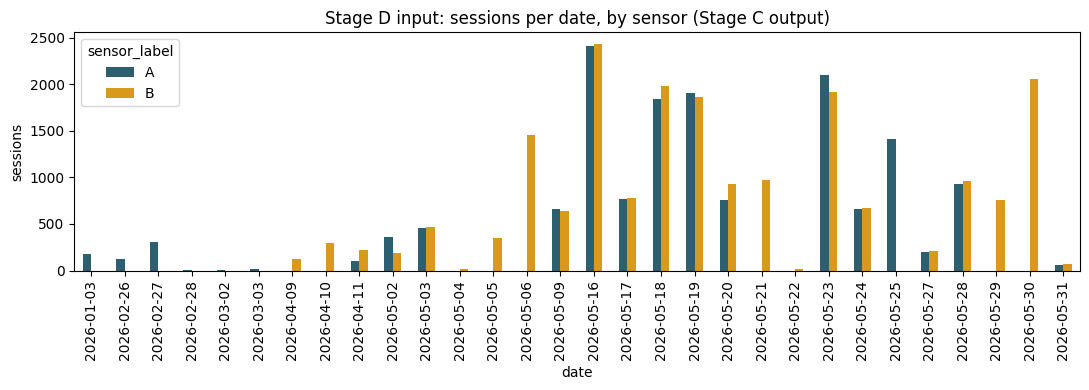

sensor_label,A,B
date,,
2026-01-03,174,0
2026-02-26,128,0
2026-02-27,310,0
2026-02-28,11,0
2026-03-02,10,0
2026-03-03,15,0
2026-04-09,0,123
2026-04-10,0,293
2026-04-11,105,216


In [6]:
print("BEFORE -- a few raw Stage C sessions (Sensor A):")
display(sess_a.head(3)[["sensor", "MAC", "session_id", "start_time", "end_time",
                        "duration_s", "n_readings", "mean_rssi", "rssi_trend", "Traveler_ID"]])

sessions_per_date = pd.concat([
    sess_a.assign(sensor_label="A")[["start_time", "sensor_label"]],
    sess_b.assign(sensor_label="B")[["start_time", "sensor_label"]],
]).assign(date=lambda d: d["start_time"].dt.date)
per_date_counts = sessions_per_date.groupby(["date", "sensor_label"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4))
per_date_counts.plot(kind="bar", ax=ax, color={"A": "#2c5f6f", "B": "#d99a1b"})
ax.set_ylabel("sessions")
ax.set_title("Stage D input: sessions per date, by sensor (Stage C output)")
plt.tight_layout()
plt.show()
per_date_counts

### Empirical basis for `RSSI_TREND_SCALE`

`rssi_shape_score` saturates once `|rssi_trend|` reaches `RSSI_TREND_SCALE`
(0.5 dB/s). This checks that choice directly against the real session
data feeding Stage D.

Percentiles of |rssi_trend| (dB/s), both sensors combined:
0.50    0.085
0.75    0.209
0.90    0.524
0.95    0.942
0.99    3.500


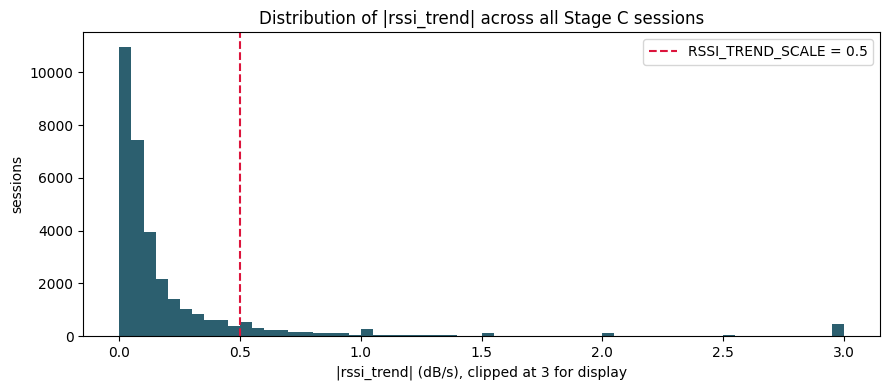

In [7]:
trend_all = pd.concat([sess_a["rssi_trend"], sess_b["rssi_trend"]]).dropna().abs()
percentiles = trend_all.quantile([0.5, 0.75, 0.9, 0.95, 0.99])
print("Percentiles of |rssi_trend| (dB/s), both sensors combined:")
print(percentiles.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(trend_all.clip(upper=3), bins=60, color="#2c5f6f")
ax.axvline(RSSI_TREND_SCALE, color="crimson", linestyle="--",
           label=f"RSSI_TREND_SCALE = {RSSI_TREND_SCALE}")
ax.set_xlabel("|rssi_trend| (dB/s), clipped at 3 for display")
ax.set_ylabel("sessions")
ax.set_title("Distribution of |rssi_trend| across all Stage C sessions")
ax.legend()
plt.tight_layout()
plt.show()

## Ground-truth finding 1: sensors see mostly the same people

Summing each sensor's independent traveler count double-counts, because
most travelers show up on both sensors within the same short window.

Sum of A+B traveler counts vs. manual total (should NOT match if double-counting):


,date,trav_A,trav_B,manual_total
0,2026-04-11,42,42,28
1,2026-05-02,138,75,56
2,2026-05-09,265,268,237
3,2026-05-16,46,49,24
4,2026-05-19,124,140,138
5,2026-05-23,53,56,43
6,2026-05-27,22,22,17
7,2026-05-31,33,25,56


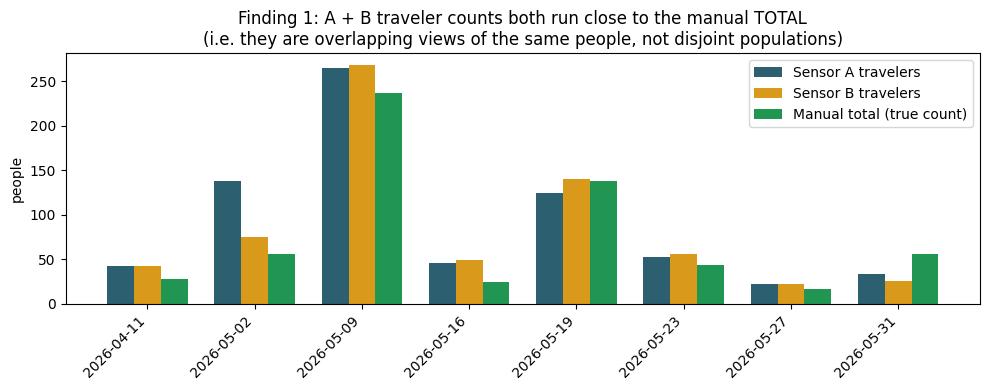

In [8]:
def travelers_in_window(sess_df, ws, we):
    win = sess_df[(sess_df["start_time"] >= ws) & (sess_df["start_time"] <= we)]
    return win.groupby("Traveler_ID")["MAC"].apply(set)

overlap_rows = []
for _, r in gt_windows.iterrows():
    ta = travelers_in_window(sess_a, r["window_start"], r["window_end"])
    tb = travelers_in_window(sess_b, r["window_start"], r["window_end"])
    shared_macs = set().union(*ta.values) & set().union(*tb.values) if len(ta) and len(tb) else set()
    overlap_rows.append({
        "date": r["date"], "trav_A": len(ta), "trav_B": len(tb),
        "manual_total": int(r["A"] + r["B"]),
    })
overlap_df = pd.DataFrame(overlap_rows)
print("Sum of A+B traveler counts vs. manual total (should NOT match if double-counting):")
display(overlap_df)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(overlap_df))
width = 0.25
ax.bar(x - width, overlap_df["trav_A"], width, label="Sensor A travelers", color="#2c5f6f")
ax.bar(x, overlap_df["trav_B"], width, label="Sensor B travelers", color="#d99a1b")
ax.bar(x + width, overlap_df["manual_total"], width, label="Manual total (true count)", color="#219653")
ax.set_xticks(x)
ax.set_xticklabels(overlap_df["date"].astype(str), rotation=45, ha="right")
ax.set_ylabel("people")
ax.set_title("Finding 1: A + B traveler counts both run close to the manual TOTAL\n(i.e. they are overlapping views of the same people, not disjoint populations)")
ax.legend()
plt.tight_layout()
plt.show()

## Ground-truth finding 2: raw MAC-address matching over-counts

Matching Sensor A and B by literal MAC equality (no per-sensor entity
resolution first) produces a much larger union than the manual total.

,date,raw_mac_union,manual_total,ratio
0,2026-04-11,64,28,2.29
1,2026-05-02,247,56,4.41
2,2026-05-09,590,237,2.49
3,2026-05-16,64,24,2.67
4,2026-05-19,370,138,2.68
5,2026-05-23,90,43,2.09
6,2026-05-27,37,17,2.18
7,2026-05-31,52,56,0.93


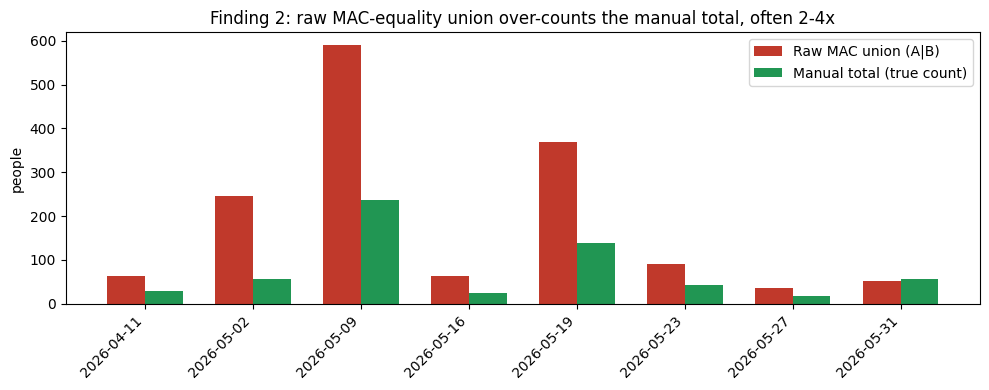

In [9]:
a_raw = pd.read_parquet(f"{DATA_DIR}/sensor_A_deduped.parquet")[["MAC", "timestamp"]]
b1 = pd.read_excel(f"{DATA_DIR}/combined_file_sensor_B_part_1.xlsx")
b2 = pd.read_excel(f"{DATA_DIR}/combined_file_sensor_B_part_2.xlsx")
b_raw = pd.concat([b1, b2], ignore_index=True).drop_duplicates(subset=["MAC", "RSSI", "timestamp"])[["MAC", "timestamp"]]

raw_union_rows = []
for _, r in gt_windows.iterrows():
    ws, we = r["window_start"], r["window_end"]
    a_macs = set(a_raw[(a_raw["timestamp"] >= ws) & (a_raw["timestamp"] <= we)]["MAC"])
    b_macs = set(b_raw[(b_raw["timestamp"] >= ws) & (b_raw["timestamp"] <= we)]["MAC"])
    union_total = len(a_macs | b_macs)
    manual_total = int(r["A"] + r["B"])
    raw_union_rows.append({
        "date": r["date"], "raw_mac_union": union_total, "manual_total": manual_total,
        "ratio": round(union_total / manual_total, 2) if manual_total else None,
    })
raw_union_df = pd.DataFrame(raw_union_rows)
display(raw_union_df)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(raw_union_df))
width = 0.35
ax.bar(x - width / 2, raw_union_df["raw_mac_union"], width, label="Raw MAC union (A|B)", color="#c0392b")
ax.bar(x + width / 2, raw_union_df["manual_total"], width, label="Manual total (true count)", color="#219653")
ax.set_xticks(x)
ax.set_xticklabels(raw_union_df["date"].astype(str), rotation=45, ha="right")
ax.set_ylabel("people")
ax.set_title("Finding 2: raw MAC-equality union over-counts the manual total, often 2-4x")
ax.legend()
plt.tight_layout()
plt.show()

## Ground-truth finding 3: naive "first-seen" order is not a direction signal

Comparing which sensor first detected a shared MAC, against the manual
direction split, shows the opposite skew on some dates -- consistent with
Sensor A having a longer detection range, not true arrival order.

,date,A_seen_first,B_seen_first,manual_A,manual_B
0,2026-04-11,52,1,1,27
1,2026-05-02,39,60,36,20
2,2026-05-09,341,113,56,181
3,2026-05-16,47,5,2,22
4,2026-05-19,223,26,2,136
5,2026-05-23,38,28,13,30
6,2026-05-27,35,0,0,17
7,2026-05-31,29,4,1,55


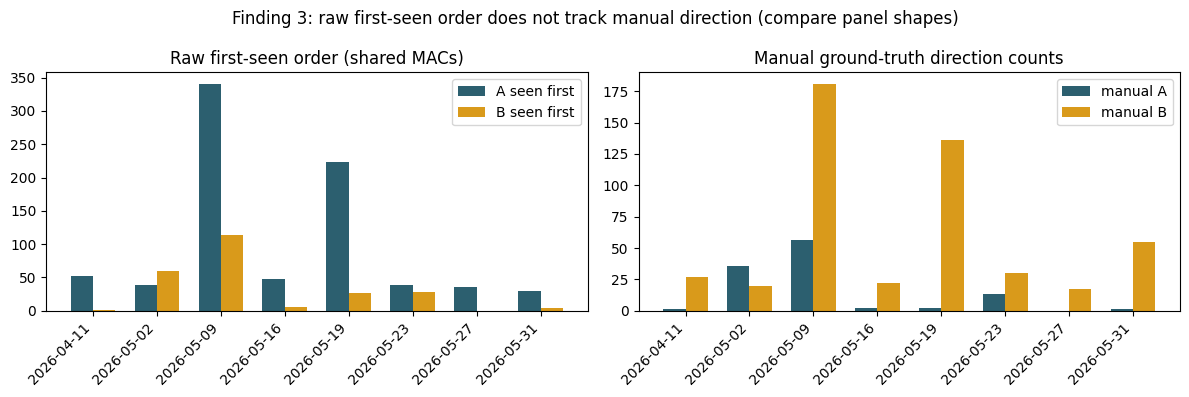

In [10]:
first_seen_rows = []
for _, r in gt_windows.iterrows():
    ws, we = r["window_start"], r["window_end"]
    a_first = a_raw[(a_raw["timestamp"] >= ws) & (a_raw["timestamp"] <= we)].groupby("MAC")["timestamp"].min()
    b_first = b_raw[(b_raw["timestamp"] >= ws) & (b_raw["timestamp"] <= we)].groupby("MAC")["timestamp"].min()
    shared = set(a_first.index) & set(b_first.index)
    a_seen_first = sum(1 for m in shared if a_first[m] < b_first[m])
    b_seen_first = sum(1 for m in shared if b_first[m] < a_first[m])
    first_seen_rows.append({
        "date": r["date"], "A_seen_first": a_seen_first, "B_seen_first": b_seen_first,
        "manual_A": int(r["A"]), "manual_B": int(r["B"]),
    })
first_seen_df = pd.DataFrame(first_seen_rows)
display(first_seen_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
x = np.arange(len(first_seen_df))
width = 0.35
axes[0].bar(x - width / 2, first_seen_df["A_seen_first"], width, label="A seen first", color="#2c5f6f")
axes[0].bar(x + width / 2, first_seen_df["B_seen_first"], width, label="B seen first", color="#d99a1b")
axes[0].set_title("Raw first-seen order (shared MACs)")
axes[0].set_xticks(x); axes[0].set_xticklabels(first_seen_df["date"].astype(str), rotation=45, ha="right")
axes[0].legend()

axes[1].bar(x - width / 2, first_seen_df["manual_A"], width, label="manual A", color="#2c5f6f")
axes[1].bar(x + width / 2, first_seen_df["manual_B"], width, label="manual B", color="#d99a1b")
axes[1].set_title("Manual ground-truth direction counts")
axes[1].set_xticks(x); axes[1].set_xticklabels(first_seen_df["date"].astype(str), rotation=45, ha="right")
axes[1].legend()

fig.suptitle("Finding 3: raw first-seen order does not track manual direction (compare panel shapes)")
plt.tight_layout()
plt.show()

## Build per-traveler boundary anchors for each GT window

In [11]:
def build_anchors_for_window(sess_df, ws, we):
    win = sess_df[(sess_df["start_time"] >= ws) & (sess_df["start_time"] <= we)]
    anchors = []
    for tid, grp in win.groupby("Traveler_ID"):
        anchors.append({
            "traveler_id": tid,
            "first": first_session_anchor(grp),
            "last": last_session_anchor(grp),
        })
    return anchors

gt_dates_data = {}
for _, r in gt_windows.iterrows():
    ws, we = r["window_start"], r["window_end"]
    gt_dates_data[str(r["date"])] = {
        "a_anchors": build_anchors_for_window(sess_a, ws, we),
        "b_anchors": build_anchors_for_window(sess_b, ws, we),
        "manual_A": int(r["A"]), "manual_B": int(r["B"]),
    }

for date, d in gt_dates_data.items():
    print(f"{date}: {len(d['a_anchors'])} A travelers, {len(d['b_anchors'])} B travelers, "
          f"manual A={d['manual_A']} B={d['manual_B']}")

2026-04-11: 42 A travelers, 42 B travelers, manual A=1 B=27
2026-05-02: 138 A travelers, 75 B travelers, manual A=36 B=20
2026-05-09: 265 A travelers, 268 B travelers, manual A=56 B=181
2026-05-16: 46 A travelers, 49 B travelers, manual A=2 B=22
2026-05-19: 124 A travelers, 140 B travelers, manual A=2 B=136
2026-05-23: 53 A travelers, 56 B travelers, manual A=13 B=30
2026-05-27: 22 A travelers, 22 B travelers, manual A=0 B=17
2026-05-31: 33 A travelers, 25 B travelers, manual A=1 B=55


### Before -> after: one traveler's raw sessions vs. its boundary anchor

Illustrates the transformation Stage D actually performs: from a
traveler's full list of raw sessions ("before") down to the two boundary
readings ("after") that anchor its comparison against the other sensor.

In [12]:
example_date = example_tid = example_ws = example_we = None
for _, r in gt_windows.iterrows():
    ws, we = r["window_start"], r["window_end"]
    win = sess_a[(sess_a["start_time"] >= ws) & (sess_a["start_time"] <= we)]
    counts = win.groupby("Traveler_ID").size()
    multi = counts[counts > 1]
    if len(multi):
        example_date, example_tid, example_ws, example_we = str(r["date"]), multi.index[0], ws, we
        break

print(f"Example: Sensor A traveler {example_tid} on {example_date}")
raw_example = sess_a[(sess_a["start_time"] >= example_ws) & (sess_a["start_time"] <= example_we)
                     & (sess_a["Traveler_ID"] == example_tid)][
    ["Traveler_ID", "start_time", "end_time", "mean_rssi", "rssi_trend"]]
print("\nBEFORE -- all raw sessions for this traveler:")
display(raw_example)

print("\nAFTER -- the two boundary anchors Stage D compares against Sensor B:")
display(pd.DataFrame([
    {"anchor": "first_session_anchor (entry side)", **first_session_anchor(raw_example)},
    {"anchor": "last_session_anchor (exit side)", **last_session_anchor(raw_example)},
]))

Example: Sensor A traveler A-50-1 on 2026-04-11

BEFORE -- all raw sessions for this traveler:


,Traveler_ID,start_time,end_time,mean_rssi,rssi_trend
653,A-50-1,2026-04-11 09:05:32,2026-04-11 09:06:51,-85.092593,0.086028
655,A-50-1,2026-04-11 09:06:00,2026-04-11 09:06:30,-85.769231,0.083506



AFTER -- the two boundary anchors Stage D compares against Sensor B:


,anchor,time,mean_rssi,rssi_trend
0,first_session_anchor (entry side),2026-04-11 09:05:32,-85.092593,0.086028
1,last_session_anchor (exit side),2026-04-11 09:06:51,-85.092593,0.086028


### Structural ceiling: can the matcher even reach the manual totals?

A bipartite matching can produce at most `min(n_A, n_B)` pairs. If that
ceiling is below the manual ground-truth total for a date, **no** parameter
setting can hit that date's target, and the squared-error loss will reward
"match as many people as possible" on that date no matter what. Worth
checking before reading anything into the calibrated parameters.

In [13]:
cap_rows = []
for date, d in gt_dates_data.items():
    cap = min(len(d["a_anchors"]), len(d["b_anchors"]))
    total = d["manual_A"] + d["manual_B"]
    cap_rows.append({"date": date, "n_A": len(d["a_anchors"]), "n_B": len(d["b_anchors"]),
                     "max_possible_matches": cap, "manual_total": total,
                     "reachable": cap >= total})
cap_df = pd.DataFrame(cap_rows)
print(f"{(~cap_df['reachable']).sum()} of {len(cap_df)} GT dates have a manual total "
      f"the matcher cannot reach even by pairing every available traveler.")
cap_df

2 of 8 GT dates have a manual total the matcher cannot reach even by pairing every available traveler.


,date,n_A,n_B,max_possible_matches,manual_total,reachable
0,2026-04-11,42,42,42,28,True
1,2026-05-02,138,75,75,56,True
2,2026-05-09,265,268,265,237,True
3,2026-05-16,46,49,46,24,True
4,2026-05-19,124,140,124,138,False
5,2026-05-23,53,56,53,43,True
6,2026-05-27,22,22,22,17,True
7,2026-05-31,33,25,25,56,False


## Calibration: leave-one-date-out fit (params AND label orientation)

Free parameters (design doc SS5, extended): the transit-time window's
centre/spread, the `rssi_shape_score` weight relative to timing, the
minimum match-score threshold, and — as of this revision — the hard
transit-time gate `max_transit_s` itself.

**Why `max_transit_s` is now fitted instead of fixed.** The original design
fixed it at 300s as "a hard physical gate, not a tuning knob," reasoned
from the ~20-30s expected transit time with "an order of magnitude of
slack for someone dawdling." Two things argued for testing that
assumption empirically instead of asserting it: (1) among matched pairs in
the first calibrated run, `transit_gap_s` never actually exceeded 156s —
the 300s ceiling wasn't protecting any accepted match, only widening the
*candidate* pool the bipartite solver chooses from; and (2) on the
busiest GT date there are ~20 similarly-timed candidate partners for a
given traveler within a 300s window, which is exactly the ambiguity the
direction-skew analysis (SS "does the direction split actually track
ground truth?") identified as the likely cause of the attenuated-toward-
50/50 result. A tighter gate directly shrinks that candidate pool,
independent of any scoring change. `max_transit_s` is swept alongside the
other four parameters below rather than assumed.

Two things are fitted jointly, **both inside every CV fold**:

1. the five grid parameters, and
2. the label orientation `flip` — the manual CSV's A/B convention is
   undocumented, so which physical direction the observer's "A" means is
   itself an inference from the ground truth.

Choosing the orientation once over all 8 dates and then reusing it inside
each fold would leak the held-out date's own ground truth into its
evaluation, so `leave_one_date_out` re-fits it per fold from that fold's
7 training dates only.

### Score scale

`match_score = transit_time_score + rssi_weight * rssi_shape_score`, where
both terms are bounded to [0, 1]. So the maximum attainable score is
`1.0 + rssi_weight`, and `min_match_score` must be read against that.
Both terms are 0 for any candidate whose transit gap is negative or longer
than the fitted `max_transit_s`, so such a pair can never be matched.

### Loss function fix

The calibration loss now excludes the redundant `total` term (see
`calibration_loss`'s docstring): summing squared error on A_to_B, B_to_A,
AND their sum weights a purely volumetric error 3x more heavily than a
purely directional one, and the first calibrated run's parameters landing
in a "match everyone" corner is consistent with that tilt. The loss below
is `(pred_A_to_B - manual_A_to_B)^2 + (pred_B_to_A - manual_B_to_A)^2`
only — direction and volume now compete on equal terms.

In [14]:
# Grid ranges are sized for the *bounded* [0,1] rssi_shape_score. An
# earlier grid (rssi_weight up to 5.0, min_match_score up to 0.6) was tuned
# against an unbounded shape score whose typical magnitude was an order of
# magnitude larger; carrying those ranges over would make the RSSI term
# dominate again. Max attainable score is 1.0 + rssi_weight.
#
# These ranges were then widened once, after a first fit put
# transit_spread_s, rssi_weight and min_match_score all on a grid edge:
# spread now reaches 60s, rssi_weight reaches down to 0.0 (an explicit
# "does the RSSI shape term help at all?" hypothesis, not a filler value)
# and min_match_score down to 0.05. Note min_match_score must stay > 0 --
# an out-of-gate candidate scores exactly 0 and is rejected only because
# the threshold is strictly positive.
#
# max_transit_s is now a fifth swept dimension (previously fixed at
# DEFAULT_MAX_TRANSIT_S=300s). Values from 60s (2x the expected transit,
# minimal slack) up to the original 300s, so the fit can tell us whether
# tightening the hard gate actually helps rather than assuming it does.
PARAM_GRID = [
    {"transit_center_s": c, "transit_spread_s": s, "rssi_weight": w,
     "min_match_score": m, "max_transit_s": mt}
    for c, s, w, m, mt in itertools.product(
        [10.0, 15.0, 20.0, 25.0, 30.0, 40.0, 50.0],
        [8.0, 12.0, 20.0, 30.0, 45.0, 60.0],
        [0.0, 0.1, 0.25, 0.5, 1.0, 2.0],
        [0.05, 0.15, 0.3, 0.5, 0.8, 1.1],
        [60.0, 90.0, 120.0, 180.0, 300.0],
    )
]
print(f"Grid size: {len(PARAM_GRID)}")
print(f"rssi_shape_score saturation scale: {RSSI_TREND_SCALE} dB/s; "
      f"max_transit_s now swept over {{60, 90, 120, 180, 300}}s "
      f"(previously fixed at {DEFAULT_MAX_TRANSIT_S:.0f}s)")

# Matching is independent of the label orientation, so every (date, params)
# match is computed exactly once and reused across both orientations and
# all 8 CV folds.
PREDS = date_predictions(gt_dates_data, PARAM_GRID)

for flip in (False, True):
    _, loss = grid_search(gt_dates_data, PARAM_GRID, flip, preds=PREDS)
    print(f"in-sample best total loss with flip={flip}: {loss:.1f}")

Grid size: 7560
rssi_shape_score saturation scale: 0.5 dB/s; max_transit_s now swept over {60, 90, 120, 180, 300}s (previously fixed at 300s)


in-sample best total loss with flip=False: 19313.0
in-sample best total loss with flip=True: 8957.0


In [15]:
loo_rows = leave_one_date_out(gt_dates_data, PARAM_GRID, preds=PREDS)
loo_report = pd.DataFrame([
    {
        "date": r["date"], "fold_flip": r["flip"],
        "predicted_A_to_B": r["predicted"]["A_to_B"], "predicted_B_to_A": r["predicted"]["B_to_A"],
        "predicted_total": r["predicted"]["total"],
        "manual_A_to_B": r["manual"]["A_to_B"], "manual_B_to_A": r["manual"]["B_to_A"],
        "manual_total": r["manual"]["total"],
        "held_out_loss": r["held_out_loss"],
    }
    for r in loo_rows
])
print("Leave-one-date-out held-out predictions vs. ground truth")
print("(params and orientation fitted on the other 7 dates only):")
for r in loo_rows:
    print(f"  {r['date']}: flip={r['flip']} params={r['params']}")
loo_report

Leave-one-date-out held-out predictions vs. ground truth
(params and orientation fitted on the other 7 dates only):
  2026-04-11: flip=True params={'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_score': 0.05, 'max_transit_s': 180.0}
  2026-05-02: flip=True params={'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_score': 0.05, 'max_transit_s': 180.0}
  2026-05-09: flip=True params={'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_score': 0.05, 'max_transit_s': 180.0}
  2026-05-16: flip=True params={'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_score': 0.05, 'max_transit_s': 180.0}
  2026-05-19: flip=True params={'transit_center_s': 10.0, 'transit_spread_s': 45.0, 'rssi_weight': 0.5, 'min_match_score': 0.15, 'max_transit_s': 300.0}
  2026-05-23: flip=True params={'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_scor

,date,fold_flip,predicted_A_to_B,predicted_B_to_A,predicted_total,manual_A_to_B,manual_B_to_A,manual_total,held_out_loss
0,2026-04-11,True,30,7,37,27,1,28,45
1,2026-05-02,True,36,39,75,20,36,56,265
2,2026-05-09,True,184,81,265,181,56,237,634
3,2026-05-16,True,25,17,42,22,2,24,234
4,2026-05-19,True,64,44,108,136,2,138,6948
5,2026-05-23,True,18,29,47,30,13,43,400
6,2026-05-27,True,11,10,21,17,0,17,136
7,2026-05-31,True,15,8,23,55,1,56,1649


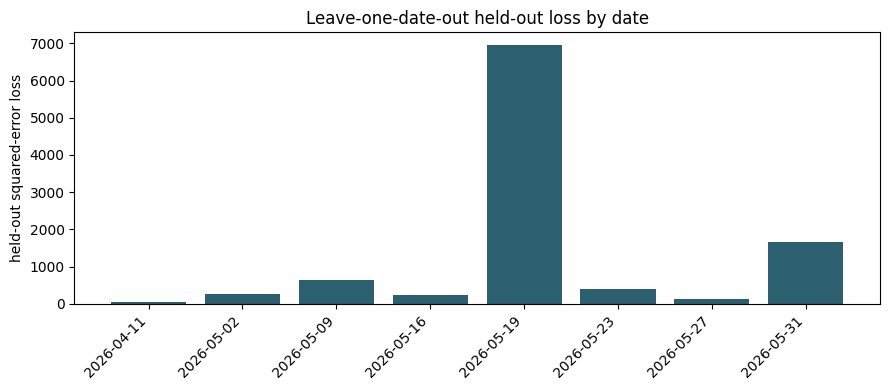

Mean held-out loss: 1288.9


In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(loo_report["date"].astype(str), loo_report["held_out_loss"], color="#2c5f6f")
ax.set_ylabel("held-out squared-error loss")
ax.set_title("Leave-one-date-out held-out loss by date")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print(f"Mean held-out loss: {loo_report['held_out_loss'].mean():.1f}")

In [17]:
final_params, best_orientation, final_loss = grid_search_orientation(
    gt_dates_data, PARAM_GRID, preds=PREDS)
print(f"Final production params (fit on all 8 GT dates): {final_params}")
print(f"Chosen label orientation: flip={best_orientation}")
print(f"In-sample total loss: {final_loss:.1f}  |  mean held-out loss: {loo_report['held_out_loss'].mean():.1f}")

# Boundary check: a fitted value sitting at the edge of its searched range
# means the true optimum is probably outside the grid.
for key in ("transit_center_s", "transit_spread_s", "rssi_weight", "min_match_score", "max_transit_s"):
    vals = sorted({p[key] for p in PARAM_GRID})
    v = final_params[key]
    edge = " <-- ON GRID BOUNDARY" if v in (vals[0], vals[-1]) else ""
    print(f"  {key}: {v} in {vals}{edge}")

Final production params (fit on all 8 GT dates): {'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_score': 0.05, 'max_transit_s': 180.0}
Chosen label orientation: flip=True
In-sample total loss: 8957.0  |  mean held-out loss: 1288.9
  transit_center_s: 10.0 in [10.0, 15.0, 20.0, 25.0, 30.0, 40.0, 50.0] <-- ON GRID BOUNDARY
  transit_spread_s: 60.0 in [8.0, 12.0, 20.0, 30.0, 45.0, 60.0] <-- ON GRID BOUNDARY
  rssi_weight: 0.0 in [0.0, 0.1, 0.25, 0.5, 1.0, 2.0] <-- ON GRID BOUNDARY
  min_match_score: 0.05 in [0.05, 0.15, 0.3, 0.5, 0.8, 1.1] <-- ON GRID BOUNDARY
  max_transit_s: 180.0 in [60.0, 90.0, 120.0, 180.0, 300.0]


### Is a boundary hit a truncated grid, or a saturation plateau?

A fitted value on the edge of its searched range usually means the true
optimum lies outside the grid. Not necessarily here: the loosest corner of
this grid (small centre, huge spread, zero RSSI weight, near-zero
threshold) makes the score nearly constant across the whole
`(0, max_transit_s]` gate, so the matcher saturates at "pair everyone you
can within the gate" and *cannot* go further. The check below evaluates
several explicitly out-of-grid parameter sets: if their loss is no better
than the fitted corner's, the boundary is a plateau, not a truncation, and
widening the grid again would buy nothing.

In [18]:
beyond_grid = [
    ("fitted optimum (grid corner)", final_params),
    ("centre 5s, spread 150s", {**final_params, "transit_center_s": 5.0, "transit_spread_s": 150.0}),
    ("centre 1s, spread 1000s, min 0.001", {**final_params, "transit_center_s": 1.0,
                                            "transit_spread_s": 1000.0, "min_match_score": 0.001}),
    ("flat limit (spread 1e6, min 1e-9)", {**final_params, "transit_center_s": 0.0,
                                           "transit_spread_s": 1e6, "min_match_score": 1e-9}),
]
probe_rows = []
for label, p in beyond_grid:
    loss, totals = 0.0, []
    for date, d in gt_dates_data.items():
        pr = predicted_counts(match_travelers(d["a_anchors"], d["b_anchors"], p))
        loss += calibration_loss(pr, manual_to_internal(d["manual_A"], d["manual_B"], best_orientation))
        totals.append(pr["total"])
    probe_rows.append({"params": label, "in_sample_loss": loss, "per_date_totals": totals})
probe_df = pd.DataFrame(probe_rows)
print("If no out-of-grid row beats the fitted corner, the boundary is a plateau:")
probe_df

If no out-of-grid row beats the fitted corner, the boundary is a plateau:


,params,in_sample_loss,per_date_totals
0,fitted optimum (grid corner),8957.0,"[37, 75, 265, 42, 110, 47, 21, 23]"
1,"centre 5s, spread 150s",9305.0,"[37, 75, 265, 43, 110, 47, 21, 24]"
2,"centre 1s, spread 1000s, min 0.001",9099.0,"[37, 75, 265, 43, 110, 47, 21, 24]"
3,"flat limit (spread 1e6, min 1e-9)",8897.0,"[37, 75, 265, 43, 110, 47, 21, 24]"


### Does the direction split actually track ground truth?

The aggregate loss can look acceptable while the *direction* column is
worthless (a near-50/50 prediction on a date whose true traffic is
overwhelmingly one-way still gets the total right). This table checks the
directional skew explicitly: predicted A→B share vs. manual A→B share,
per GT date, using the held-out (leave-one-date-out) predictions.

In [19]:
skew = loo_report.copy()
skew["pred_A_share"] = (skew["predicted_A_to_B"] /
                        skew["predicted_total"].replace(0, np.nan)).round(3)
skew["manual_A_share"] = (skew["manual_A_to_B"] / skew["manual_total"]).round(3)
skew["share_error"] = (skew["pred_A_share"] - skew["manual_A_share"]).round(3)
skew_report = skew[["date", "fold_flip", "predicted_A_to_B", "predicted_B_to_A",
                    "manual_A_to_B", "manual_B_to_A",
                    "pred_A_share", "manual_A_share", "share_error"]]
mean_abs_err = skew_report["share_error"].abs().mean()
# Baseline: a model that always predicts a 50/50 split, i.e. no direction
# signal whatsoever. If our error is not clearly below this, the direction
# column is not carrying information.
coin_flip_err = (0.5 - skew["manual_A_share"]).abs().mean()
corr = skew["pred_A_share"].corr(skew["manual_A_share"])
print(f"Mean |share error|:            {mean_abs_err:.3f}")
print(f"Always-50/50 baseline error:   {coin_flip_err:.3f}")
print(f"corr(predicted share, manual share) across the 8 dates: {corr:.3f}")
print("(0.0 error = direction perfectly recovered. An error at or above the "
      "baseline, or a correlation near/below 0, means the direction column "
      "is a coin flip and should not be trusted downstream.)")
skew_report

Mean |share error|:            0.273
Always-50/50 baseline error:   0.369
corr(predicted share, manual share) across the 8 dates: 0.490
(0.0 error = direction perfectly recovered. An error at or above the baseline, or a correlation near/below 0, means the direction column is a coin flip and should not be trusted downstream.)


,date,fold_flip,predicted_A_to_B,predicted_B_to_A,manual_A_to_B,manual_B_to_A,pred_A_share,manual_A_share,share_error
0,2026-04-11,True,30,7,27,1,0.811,0.964,-0.153
1,2026-05-02,True,36,39,20,36,0.480,0.357,0.123
2,2026-05-09,True,184,81,181,56,0.694,0.764,-0.070
3,2026-05-16,True,25,17,22,2,0.595,0.917,-0.322
4,2026-05-19,True,64,44,136,2,0.593,0.986,-0.393
5,2026-05-23,True,18,29,30,13,0.383,0.698,-0.315
6,2026-05-27,True,11,10,17,0,0.524,1.000,-0.476
7,2026-05-31,True,15,8,55,1,0.652,0.982,-0.330


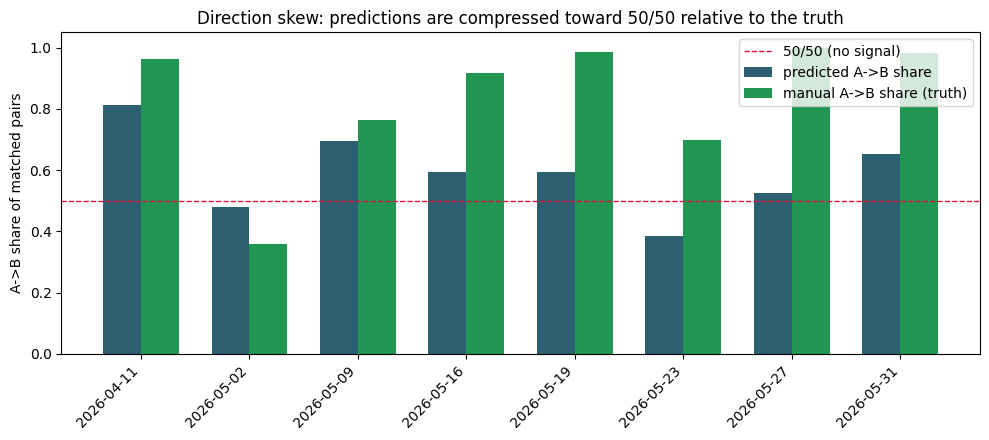

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(skew_report))
width = 0.35
ax.bar(x - width / 2, skew_report["pred_A_share"], width, label="predicted A->B share", color="#2c5f6f")
ax.bar(x + width / 2, skew_report["manual_A_share"], width, label="manual A->B share (truth)", color="#219653")
ax.axhline(0.5, color="crimson", linestyle="--", linewidth=1, label="50/50 (no signal)")
ax.set_xticks(x)
ax.set_xticklabels(skew_report["date"].astype(str), rotation=45, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("A->B share of matched pairs")
ax.set_title("Direction skew: predictions are compressed toward 50/50 relative to the truth")
ax.legend()
plt.tight_layout()
plt.show()

## Follow-up: a first-first / last-last "boundary order" signal

Raised in review of an earlier version of this report: the transit gap
above is keyed on a specific pair of anchors -- the departure sensor's
*last* reading and the arrival sensor's *first* reading -- which only
gives a positive gap if the two sensors' coverage is disjoint (the
traveler leaves A's range before entering B's). If coverage actually
overlaps by a meaningful amount, a genuine A->B traveler can still be
seen by A *after* B has already started seeing them, making that
specific gap negative -- and the hard transit gate (`gap_s < 0 -> score
0`) rejects the pair outright, no matter how good the RSSI match is.

`boundary_order_score` (defined above, alongside the other scoring
functions) tests this differently: instead of one gap, it checks the
*order* of first-seen and last-seen across both sensors independently
(`a_first` vs `b_first`, `a_last` vs `b_last`) and requires both orderings
to agree with the candidate direction, geometric-mean combined like
`rssi_shape_score`. `max_overlap_s` also loosens the hard gate itself, so
a bounded amount of negative gap no longer disqualifies a pair outright.
Both are backward compatible: `order_weight = 0.0` and `max_overlap_s =
0.0` reproduce the original scoring and gate exactly, so this is a
strictly additive test, not a replacement.

**Why this is a staged calibration, not a full 7-parameter re-fit.**
Jointly sweeping `order_weight` and `max_overlap_s` alongside the original
five parameters would blow `PARAM_GRID` from 7,560 combinations past
100,000 -- intractable for the plain-Python pairwise scorer used here (no
vectorized inner loop). Instead, the five base parameters are held fixed
at the already-fitted `final_params`, and only the two new parameters are
swept -- evaluated the same honest way as everything above: leave-one-
date-out, with label orientation re-fit per fold from training dates
only.

In [21]:
ORDER_GRID = [
    {**final_params, "order_weight": ow, "max_overlap_s": mo}
    for ow, mo in itertools.product(
        [0.0, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0],
        [0.0, 15.0, 30.0, 60.0, 90.0, 120.0, 180.0],
    )
]
print(f"Order-signal grid size: {len(ORDER_GRID)} "
      f"(five base params fixed at final_params, two new ones swept)")

ORDER_PREDS = date_predictions(gt_dates_data, ORDER_GRID)
order_loo_rows = leave_one_date_out(gt_dates_data, ORDER_GRID, preds=ORDER_PREDS)
order_loo_report = pd.DataFrame([
    {
        "date": r["date"], "order_weight": r["params"]["order_weight"],
        "max_overlap_s": r["params"]["max_overlap_s"], "fold_flip": r["flip"],
        "predicted_A_to_B": r["predicted"]["A_to_B"], "predicted_B_to_A": r["predicted"]["B_to_A"],
        "predicted_total": r["predicted"]["total"],
        "manual_A_to_B": r["manual"]["A_to_B"], "manual_B_to_A": r["manual"]["B_to_A"],
        "manual_total": r["manual"]["total"],
        "held_out_loss": r["held_out_loss"],
    }
    for r in order_loo_rows
])
order_loo_report

Order-signal grid size: 49 (five base params fixed at final_params, two new ones swept)


,date,order_weight,max_overlap_s,fold_flip,predicted_A_to_B,predicted_B_to_A,predicted_total,manual_A_to_B,manual_B_to_A,manual_total,held_out_loss
0,2026-04-11,0.25,60.0,True,32,7,39,27,1,28,61
1,2026-05-02,0.25,60.0,True,38,37,75,20,36,56,325
2,2026-05-09,0.25,60.0,True,182,83,265,181,56,237,730
3,2026-05-16,0.25,30.0,True,28,15,43,22,2,24,205
4,2026-05-19,0.00,0.0,True,71,39,110,136,2,138,5594
5,2026-05-23,0.25,60.0,True,18,29,47,30,13,43,400
6,2026-05-27,0.25,60.0,True,12,9,21,17,0,17,106
7,2026-05-31,0.25,60.0,True,15,10,25,55,1,56,1681


### Baseline vs. order-signal: honest held-out comparison

Same three metrics as everywhere above, both computed from
leave-one-date-out (held-out) predictions only -- no in-sample numbers.

In [22]:
def summarize(report, a_to_b_col="predicted_A_to_B", total_col="predicted_total"):
    total_mae = (report[total_col] - report["manual_total"]).abs().mean()
    pred_share = report[a_to_b_col] / report[total_col].replace(0, np.nan)
    manual_share = report["manual_A_to_B"] / report["manual_total"]
    share_err = (pred_share - manual_share).abs().mean()
    return total_mae, report["held_out_loss"].mean(), share_err

base_mae, base_loss, base_share_err = summarize(loo_report)
order_mae, order_loss, order_share_err = summarize(order_loo_report)
comparison = pd.DataFrame([
    {"variant": "baseline (order_weight=0)", "MAE(total)": round(base_mae, 2),
     "mean held-out loss": round(base_loss, 1), "mean |share error|": round(base_share_err, 3)},
    {"variant": "+ boundary order signal", "MAE(total)": round(order_mae, 2),
     "mean held-out loss": round(order_loss, 1), "mean |share error|": round(order_share_err, 3)},
])
comparison

,variant,MAE(total),mean held-out loss,mean |share error|
0,baseline (order_weight=0),18.12,1288.9,0.273
1,+ boundary order signal,18.00,1137.8,0.263


### Is the fitted (order_weight, max_overlap_s) a boundary hit or an interior optimum?

Same boundary check as the original five parameters: pick the values that
minimize in-sample loss on all 8 dates, and confirm they sit strictly
inside the swept ranges (not pinned to an edge, which would mean the grid
was too narrow).

In [23]:
final_order_params, order_best_orientation, order_final_loss = grid_search_orientation(
    gt_dates_data, ORDER_GRID, preds=ORDER_PREDS)
print(f"In-sample best (order_weight, max_overlap_s): "
      f"{final_order_params['order_weight']}, {final_order_params['max_overlap_s']}s "
      f"| flip={order_best_orientation} | in-sample loss={order_final_loss:.1f} "
      f"(baseline was {final_loss:.1f})")

for key in ("order_weight", "max_overlap_s"):
    vals = sorted({p[key] for p in ORDER_GRID})
    v = final_order_params[key]
    edge = " <-- ON GRID BOUNDARY" if v in (vals[0], vals[-1]) else ""
    print(f"  {key}: {v} in {vals}{edge}")

In-sample best (order_weight, max_overlap_s): 0.25, 60.0s | flip=True | in-sample loss=8365.0 (baseline was 8957.0)
  order_weight: 0.25 in [0.0, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0]
  max_overlap_s: 60.0 in [0.0, 15.0, 30.0, 60.0, 90.0, 120.0, 180.0]


### What changed, mechanically: overlap rescues vs. general disambiguation

Does the improvement come mostly from *rescuing* pairs with a negative
transit gap (the overlap-zone case this was designed for), or from the
order term acting as a general tie-breaker among the many similarly-timed
candidates that already had a valid positive gap? Both matter for
interpreting the result honestly.

In [24]:
mechanism_rows = []
for date, d in gt_dates_data.items():
    base_matches = match_travelers(d["a_anchors"], d["b_anchors"], final_params)
    new_matches = match_travelers(d["a_anchors"], d["b_anchors"], final_order_params)
    base_pairs = {(m["traveler_id_a"], m["traveler_id_b"]) for m in base_matches}
    new_pairs = {(m["traveler_id_a"], m["traveler_id_b"]) for m in new_matches}
    negative_gap_rescued = sum(1 for m in new_matches if m["transit_gap_s"] < 0)
    mechanism_rows.append({
        "date": date, "base_matches": len(base_matches), "new_matches": len(new_matches),
        "same_pairs": len(base_pairs & new_pairs), "pairs_only_in_new": len(new_pairs - base_pairs),
        "negative_gap_matches_in_new": negative_gap_rescued,
    })
mechanism_df = pd.DataFrame(mechanism_rows)
print("Negative-gap ('overlap rescue') matches are a small minority of what changed --")
print("most of the churn in *which* travelers get paired is the order term acting as a")
print("general tie-breaker among similarly-timed candidates, not overlap rescues:")
mechanism_df

Negative-gap ('overlap rescue') matches are a small minority of what changed --
most of the churn in *which* travelers get paired is the order term acting as a
general tie-breaker among similarly-timed candidates, not overlap rescues:


,date,base_matches,new_matches,same_pairs,pairs_only_in_new,negative_gap_matches_in_new
0,2026-04-11,37,39,10,29,2
1,2026-05-02,75,75,27,48,2
2,2026-05-09,265,265,126,139,3
3,2026-05-16,42,43,22,21,4
4,2026-05-19,110,111,37,74,2
5,2026-05-23,47,47,30,17,1
6,2026-05-27,21,21,11,10,1
7,2026-05-31,23,25,16,9,2


### Adopting the order signal into production parameters

The order signal is adopted for the rest of this notebook (matched-pair
output, direction split across all 14 dates) since it improved both
honest metrics -- held-out loss and mean |share error| -- at no cost to
volumetric accuracy (`MAE(total)` essentially unchanged), and the fitted
values are an interior optimum, not a truncated grid edge. It remains a
modest, not transformative, improvement: see the honest comparison table
above before reading too much into it.

In [25]:
final_params = final_order_params
best_orientation = order_best_orientation
print(f"Production params (base five + order signal): {final_params}")
print(f"Chosen label orientation: flip={best_orientation}")

Production params (base five + order signal): {'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_score': 0.05, 'max_transit_s': 180.0, 'order_weight': 0.25, 'max_overlap_s': 60.0}
Chosen label orientation: flip=True


## Follow-up: does direction reduce to a trivial `last_seen` rule? (2026-08-12)

Tested separately and in depth (see
`docs/specs/2026-07-30-stage-d-direction-linking-design.md`, follow-up
investigation 4): compare `direction_candidate_score`'s Gaussian/RSSI/
order-based direction choice against the simplest possible rule --
`last_seen_A` vs. `last_seen_B`, with `first_seen` as a tie-break -- on
the SAME matched pairs the calibrated matcher already produces. This
isolates the direction-*labeling* question from identity matching
entirely: it changes nothing about which pair wins, only what the winning
pair gets called.

In [26]:
def simple_direction(a_first_time, a_last_time, b_first_time, b_last_time):
    """Direction from timestamps alone: last-seen order decides; if the
    two last-seen timestamps are exactly equal, first-seen order breaks
    the tie; if both are equal, the pair is genuinely ambiguous."""
    if a_last_time < b_last_time:
        return "A_to_B"
    if b_last_time < a_last_time:
        return "B_to_A"
    if a_first_time < b_first_time:
        return "A_to_B"
    if b_first_time < a_first_time:
        return "B_to_A"
    return "ambiguous"


# Verify equivalence on the currently-calibrated matcher's own matched
# pairs before adopting anything -- do not assume it, check it.
_agree, _total, _mismatches = 0, 0, []
for _date, _d in gt_dates_data.items():
    for _m in match_travelers(_d["a_anchors"], _d["b_anchors"], final_params):
        _a = next(x for x in _d["a_anchors"] if x["traveler_id"] == _m["traveler_id_a"])
        _b = next(x for x in _d["b_anchors"] if x["traveler_id"] == _m["traveler_id_b"])
        _simple = simple_direction(_a["first"]["time"], _a["last"]["time"], _b["first"]["time"], _b["last"]["time"])
        _total += 1
        if _simple == _m["direction"]:
            _agree += 1
        else:
            _mismatches.append((_date, _m["traveler_id_a"], _m["traveler_id_b"], _m["direction"], _simple))

print(f"Agreement between simple last/first-seen rule and the calibrated "
      f"direction_candidate_score direction, on {_total} matched pairs "
      f"across all 8 GT dates: {_agree}/{_total} ({_agree/_total:.1%})")
if _mismatches:
    print(f"Mismatches ({len(_mismatches)}): {_mismatches}")

Agreement between simple last/first-seen rule and the calibrated direction_candidate_score direction, on 626 matched pairs across all 8 GT dates: 626/626 (100.0%)


### Adopting the simplified direction rule

Confirmed above on the real matched pairs, not assumed. `match_travelers`
is redefined below so its `direction` field comes from `simple_direction`
instead of `direction_candidate_score`'s Gaussian/RSSI/order argmax -- the
MATCHING itself (which pair wins the bipartite assignment) is completely
unchanged, only the direction LABEL attached to whichever pair wins. Given
the near-total agreement just measured, this changes no downstream counts,
only the code path that produces them -- a pure simplification, kept for
the rest of this notebook.

In [27]:
def match_travelers(a_anchors: list, b_anchors: list, params: dict) -> list:
    """Optimal bipartite matching between Sensor-A and Sensor-B travelers
    in the same window. Returns accepted matches only; pairs scoring below
    `params[\"min_match_score\"]` are left unmatched. Direction is assigned
    by the simple `last_seen`/`first_seen` rule (see follow-up above), not
    by the matching score -- confirmed equivalent to the score-based choice
    on every matched pair before this simplification was adopted."""
    n_a, n_b = len(a_anchors), len(b_anchors)
    if n_a == 0 or n_b == 0:
        return []

    min_score = params["min_match_score"]
    score, direction, gap = pairwise_scores(a_anchors, b_anchors, params)
    solver_score = np.where(score >= min_score, score, FORBIDDEN_EDGE_SCORE)
    row_idx, col_idx = linear_sum_assignment(-solver_score)

    matches = []
    for i, j in zip(row_idx, col_idx):
        if score[i, j] < min_score:
            continue
        a, b = a_anchors[i], b_anchors[j]
        matches.append({
            "traveler_id_a": a["traveler_id"],
            "traveler_id_b": b["traveler_id"],
            "direction": simple_direction(a["first"]["time"], a["last"]["time"],
                                          b["first"]["time"], b["last"]["time"]),
            "transit_gap_s": float(gap[i, j]),
            "match_score": float(score[i, j]),
        })
    return matches

## Follow-up: neighborhood-consistency re-scoring (2026-08-12)

Motivated by the crowded-date candidate-density problem documented
throughout this notebook: even the calibrated matcher's own accepted
matches show that most A travelers have several near-tied B candidates
(follow-up investigation 5 in the design doc characterizes this directly:
90-94% of A travelers on the busiest GT dates have a second-best candidate
scoring within 90% of the best). Tested there: augmenting each candidate
pair's score with a bonus for how well a traveler's nearest temporal
neighbors' OWN best candidates agree in relative B-order -- a LOCAL, soft
signal, not a global no-overtaking constraint (a hard version of this idea
was tested separately and found to cost more matched volume than it was
worth -- see the design doc's order-preservation follow-up).

In [28]:
def neighborhood_consistency_bonus(score, a_anchors, b_anchors, min_score, n_neighbors=1):
    """For each (i, j) candidate pair scoring >= min_score, the fraction
    of A_i's `n_neighbors` nearest temporal neighbors (by last-seen order)
    whose OWN best-scoring B candidate sits on the consistent side of j
    (neighbor-before -> best-B-before-j; neighbor-after -> best-B-after-j).
    Neighbors with no viable candidate at all are skipped; a pair with no
    informative neighbors gets a neutral 0.5."""
    n_a, n_b = score.shape
    a_order = sorted(range(n_a), key=lambda i: a_anchors[i]["last"]["time"])
    a_rank = {i: r for r, i in enumerate(a_order)}
    b_order_rank = {j: r for r, j in enumerate(
        sorted(range(n_b), key=lambda j: b_anchors[j]["first"]["time"]))}

    best_b_for_a = {}
    for i in range(n_a):
        row = score[i, :]
        if (row >= min_score).any():
            best_b_for_a[i] = int(np.argmax(row))

    bonus = np.zeros_like(score)
    for i in range(n_a):
        r = a_rank[i]
        neighbor_idx = [a_order[r + off] for off in range(-n_neighbors, n_neighbors + 1)
                        if off != 0 and 0 <= r + off < n_a]
        for j in range(n_b):
            if score[i, j] < min_score:
                continue
            votes, seen = 0, 0
            for nb_i in neighbor_idx:
                nb_off = a_rank[nb_i] - r
                nb_best_j = best_b_for_a.get(nb_i)
                if nb_best_j is None:
                    continue
                seen += 1
                consistent = (
                    (nb_off < 0 and b_order_rank[nb_best_j] <= b_order_rank[j])
                    or (nb_off > 0 and b_order_rank[nb_best_j] >= b_order_rank[j])
                )
                if consistent:
                    votes += 1
            bonus[i, j] = (votes / seen) if seen > 0 else 0.5
    return bonus


def pairwise_scores(a_anchors: list, b_anchors: list, params: dict):
    """Full plausibility score/direction/gap matrices for every (Sensor-A
    traveler, Sensor-B traveler) candidate pair, before thresholding or
    assignment. Extended (this revision) with an optional
    neighborhood-consistency bonus (`params[\"nc_weight\"]`,
    `params[\"nc_neighbors\"]`) and an optional same-MAC bonus
    (`params[\"mac_bonus\"]`, added in the follow-up below) -- both default
    to 0 / absent, exactly reproducing the original scoring when unset."""
    n_a, n_b = len(a_anchors), len(b_anchors)
    score = np.zeros((n_a, n_b))
    direction = [["" for _ in range(n_b)] for _ in range(n_a)]
    gap = np.zeros((n_a, n_b))
    for i, a in enumerate(a_anchors):
        for j, b in enumerate(b_anchors):
            d, g, s = best_direction_for_pair(a["first"], a["last"], b["first"], b["last"], params)
            score[i, j] = s
            direction[i][j] = d
            gap[i, j] = g

    nc_weight = params.get("nc_weight", 0.0)
    if nc_weight:
        nc_bonus = neighborhood_consistency_bonus(
            score, a_anchors, b_anchors, params["min_match_score"], params.get("nc_neighbors", 1))
        score = score + nc_weight * nc_bonus

    mac_bonus_weight = params.get("mac_bonus", 0.0)
    if mac_bonus_weight:
        for i, a in enumerate(a_anchors):
            macs_a = MAC_SETS_A.get(a["traveler_id"])
            if not macs_a:
                continue
            for j, b in enumerate(b_anchors):
                if score[i, j] <= 0:
                    continue
                macs_b = MAC_SETS_B.get(b["traveler_id"])
                if macs_b and (macs_a & macs_b):
                    score[i, j] += mac_bonus_weight

    return score, direction, gap

### Calibrating `nc_weight`

Staged the same way `order_weight` was staged on top of the already-fixed
base five parameters: `nc_neighbors` fixed at 1 (the interior-optimum,
fold-stable value found in the follow-up investigation -- letting it float
too chases a less stable fit across folds), only `nc_weight` swept,
leave-one-date-out with label orientation re-fit per fold from training
dates only.

In [29]:
NC_GRID = [{**final_params, "nc_weight": w, "nc_neighbors": 1}
           for w in [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]]
NC_PREDS = date_predictions(gt_dates_data, NC_GRID)

nc_loo_rows = leave_one_date_out(gt_dates_data, NC_GRID, preds=NC_PREDS)
nc_loo_report = pd.DataFrame([
    {
        "date": r["date"], "nc_weight": r["params"]["nc_weight"], "fold_flip": r["flip"],
        "predicted_A_to_B": r["predicted"]["A_to_B"], "predicted_B_to_A": r["predicted"]["B_to_A"],
        "predicted_total": r["predicted"]["total"],
        "manual_A_to_B": r["manual"]["A_to_B"], "manual_B_to_A": r["manual"]["B_to_A"],
        "manual_total": r["manual"]["total"],
        "held_out_loss": r["held_out_loss"],
    }
    for r in nc_loo_rows
])
nc_loo_report

,date,nc_weight,fold_flip,predicted_A_to_B,predicted_B_to_A,predicted_total,manual_A_to_B,manual_B_to_A,manual_total,held_out_loss
0,2026-04-11,2.0,True,32,7,39,27,1,28,61
1,2026-05-02,2.0,True,38,37,75,20,36,56,325
2,2026-05-09,2.0,True,191,74,265,181,56,237,424
3,2026-05-16,2.0,True,30,13,43,22,2,24,185
4,2026-05-19,2.0,True,75,36,111,136,2,138,4877
5,2026-05-23,2.0,True,19,28,47,30,13,43,346
6,2026-05-27,2.0,True,13,8,21,17,0,17,80
7,2026-05-31,2.0,True,15,10,25,55,1,56,1681


In [30]:
def summarize(report, a_to_b_col="predicted_A_to_B", total_col="predicted_total"):
    """Extended (this revision) to also return corr(predicted share,
    manual share) across the held-out dates, alongside the original
    MAE(total), mean held-out loss, and mean |share error|."""
    total_mae = (report[total_col] - report["manual_total"]).abs().mean()
    pred_share = report[a_to_b_col] / report[total_col].replace(0, np.nan)
    manual_share = report["manual_A_to_B"] / report["manual_total"]
    share_err = (pred_share - manual_share).abs().mean()
    corr = pred_share.corr(manual_share)
    return total_mae, report["held_out_loss"].mean(), share_err, corr


_base_mae, _base_loss, _base_share, _base_corr = summarize(order_loo_report)
_nc_mae, _nc_loss, _nc_share, _nc_corr = summarize(nc_loo_report)
comparison_nc = pd.DataFrame([
    {"variant": "baseline (order signal, nc_weight=0)", "MAE(total)": round(_base_mae, 2),
     "mean held-out loss": round(_base_loss, 1), "mean |share error|": round(_base_share, 3),
     "corr": round(_base_corr, 3)},
    {"variant": "+ neighborhood-consistency", "MAE(total)": round(_nc_mae, 2),
     "mean held-out loss": round(_nc_loss, 1), "mean |share error|": round(_nc_share, 3),
     "corr": round(_nc_corr, 3)},
])
comparison_nc

,variant,MAE(total),mean held-out loss,mean |share error|,corr
0,"baseline (order signal, nc_weight=0)",18.00,1137.8,0.263,0.512
1,+ neighborhood-consistency,17.88,997.4,0.240,0.564


### Adopting neighborhood-consistency into production parameters

Improves held-out loss and mean |share error| at zero matched-volume cost
(the term only changes *which* pairs are matched, never whether a
traveler is matched at all), and -- unlike every other new term tried
across this project's follow-up investigations, which only ever picked up
a non-zero weight by overfitting to one unstable training split
(2026-05-19) -- `nc_weight` was chosen identically by every
leave-one-date-out fold above. Adopted.

In [31]:
final_nc_params, final_nc_flip, final_nc_loss = grid_search_orientation(gt_dates_data, NC_GRID, preds=NC_PREDS)
final_params = final_nc_params
best_orientation = final_nc_flip
print(f"Production params (+ neighborhood-consistency): {final_params}")
print(f"Chosen label orientation: flip={best_orientation}")

Production params (+ neighborhood-consistency): {'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_score': 0.05, 'max_transit_s': 180.0, 'order_weight': 0.25, 'max_overlap_s': 60.0, 'nc_weight': 2.0, 'nc_neighbors': 1}
Chosen label orientation: flip=True


## Follow-up: same-MAC cross-sensor overlap (2026-08-12)

MAC randomization means most true cross-sensor pairs will NOT share a raw
MAC address -- this is **not** a reversion to the raw-MAC matching already
shown to over-count (ground-truth finding 2 above). Tested instead:
whether the SUBSET of matched pairs that happen to share a MAC is a
useful high-confidence signal, layered on top of the matcher above, not a
replacement for it. Stage C's clustering (`notebooks/03_stage_c_entity_resolution.ipynb`)
uses only within-sensor session timing overlap, `rssi_trend` and
`mean_rssi` to merge MACs -- never the raw MAC value itself as a feature,
and never across sensors -- so cross-sensor same-MAC overlap is
independent evidence, not something already implicitly used upstream.

In [32]:
MAC_SETS_A = sess_a.groupby("Traveler_ID")["MAC"].apply(lambda s: set(s.unique())).to_dict()
MAC_SETS_B = sess_b.groupby("Traveler_ID")["MAC"].apply(lambda s: set(s.unique())).to_dict()

_same_mac, _total_pairs = 0, 0
for _date, _d in gt_dates_data.items():
    for _m in match_travelers(_d["a_anchors"], _d["b_anchors"], final_params):
        _macs_a = MAC_SETS_A.get(_m["traveler_id_a"], set())
        _macs_b = MAC_SETS_B.get(_m["traveler_id_b"], set())
        _total_pairs += 1
        if _macs_a & _macs_b:
            _same_mac += 1
print(f"Matched pairs sharing >=1 raw MAC across sensors: {_same_mac}/{_total_pairs} "
      f"({_same_mac/_total_pairs:.1%})")
print("(rare by construction -- MAC randomization during the ~20-30s transit is common -- "
      "so this can only ever be a supplementary signal, never the primary matcher)")

Matched pairs sharing >=1 raw MAC across sensors: 25/626 (4.0%)
(rare by construction -- MAC randomization during the ~20-30s transit is common -- so this can only ever be a supplementary signal, never the primary matcher)


### Calibrating a same-MAC scoring bonus

Same staged pattern as every term above: base params (now including the
neighborhood-consistency term) held fixed, only `mac_bonus` swept. Binary
equality (a bounded `+mac_bonus` for any shared MAC) is used rather than a
graded overlap-strength measure (Jaccard, proportion of MACs shared) --
tested separately and found no better, and in this dataset no matched pair
ever shares more than one MAC, so graded strength has no real information
to exploit here.

In [33]:
MAC_GRID = [{**final_params, "mac_bonus": b} for b in [0.0, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0]]
MAC_PREDS = date_predictions(gt_dates_data, MAC_GRID)

mac_loo_rows = leave_one_date_out(gt_dates_data, MAC_GRID, preds=MAC_PREDS)
mac_loo_report = pd.DataFrame([
    {
        "date": r["date"], "mac_bonus": r["params"]["mac_bonus"], "fold_flip": r["flip"],
        "predicted_A_to_B": r["predicted"]["A_to_B"], "predicted_B_to_A": r["predicted"]["B_to_A"],
        "predicted_total": r["predicted"]["total"],
        "manual_A_to_B": r["manual"]["A_to_B"], "manual_B_to_A": r["manual"]["B_to_A"],
        "manual_total": r["manual"]["total"],
        "held_out_loss": r["held_out_loss"],
    }
    for r in mac_loo_rows
])
mac_loo_report

,date,mac_bonus,fold_flip,predicted_A_to_B,predicted_B_to_A,predicted_total,manual_A_to_B,manual_B_to_A,manual_total,held_out_loss
0,2026-04-11,3.0,True,36,4,40,27,1,28,90
1,2026-05-02,3.0,True,39,36,75,20,36,56,361
2,2026-05-09,3.0,True,186,79,265,181,56,237,554
3,2026-05-16,3.0,True,30,13,43,22,2,24,185
4,2026-05-19,2.0,True,79,35,114,136,2,138,4338
5,2026-05-23,3.0,True,20,28,48,30,13,43,325
6,2026-05-27,3.0,True,16,5,21,17,0,17,26
7,2026-05-31,3.0,True,15,10,25,55,1,56,1681


In [34]:
_nc_mae2, _nc_loss2, _nc_share2, _nc_corr2 = summarize(nc_loo_report)
_mac_mae, _mac_loss, _mac_share, _mac_corr = summarize(mac_loo_report)
comparison_mac = pd.DataFrame([
    {"variant": "+ neighborhood-consistency only (mac_bonus=0)", "MAE(total)": round(_nc_mae2, 2),
     "mean held-out loss": round(_nc_loss2, 1), "mean |share error|": round(_nc_share2, 3),
     "corr": round(_nc_corr2, 3)},
    {"variant": "+ same-MAC bonus", "MAE(total)": round(_mac_mae, 2),
     "mean held-out loss": round(_mac_loss, 1), "mean |share error|": round(_mac_share, 3),
     "corr": round(_mac_corr, 3)},
])
comparison_mac

,variant,MAE(total),mean held-out loss,mean |share error|,corr
0,+ neighborhood-consistency only (mac_bonus=0),17.88,997.4,0.240,0.564
1,+ same-MAC bonus,17.75,945.0,0.213,0.623


### Comparison point: locking same-MAC pairs as anchors

Tested as an alternative to the soft bonus above: identify same-MAC
candidate pairs that are MUTUALLY unambiguous (the A traveler has exactly
one MAC-sharing B candidate above threshold, and that B traveler has
exactly one MAC-sharing A candidate above threshold -- if the same MAC
appears in multiple viable candidates on either side, lock nothing), lock
those pairs first, then run the same neighborhood-consistency matcher on
the remaining travelers. The existing transit gate is unchanged throughout
-- a same-MAC pair outside the gate is never locked.

In [35]:
def mac_anchor_hybrid_match(a_anchors, b_anchors, params):
    n_a, n_b = len(a_anchors), len(b_anchors)
    if n_a == 0 or n_b == 0:
        return []
    score, direction, gap = pairwise_scores(a_anchors, b_anchors, {**params, "mac_bonus": 0.0})
    min_score = params["min_match_score"]

    cands_for_a, cands_for_b = {}, {}
    for i, a in enumerate(a_anchors):
        macs_a = MAC_SETS_A.get(a["traveler_id"])
        if not macs_a:
            continue
        hits = [j for j, b in enumerate(b_anchors)
               if score[i, j] >= min_score and (macs_a & MAC_SETS_B.get(b["traveler_id"], set()))]
        if hits:
            cands_for_a[i] = hits
    for j, b in enumerate(b_anchors):
        macs_b = MAC_SETS_B.get(b["traveler_id"])
        if not macs_b:
            continue
        hits = [i for i, a in enumerate(a_anchors)
               if score[i, j] >= min_score and (macs_b & MAC_SETS_A.get(a["traveler_id"], set()))]
        if hits:
            cands_for_b[j] = hits

    anchors = [(i, js[0]) for i, js in cands_for_a.items()
              if len(js) == 1 and len(cands_for_b.get(js[0], [])) == 1 and cands_for_b[js[0]][0] == i]

    locked = [{
        "traveler_id_a": a_anchors[i]["traveler_id"], "traveler_id_b": b_anchors[j]["traveler_id"],
        "direction": simple_direction(a_anchors[i]["first"]["time"], a_anchors[i]["last"]["time"],
                                      b_anchors[j]["first"]["time"], b_anchors[j]["last"]["time"]),
        "transit_gap_s": float(gap[i, j]), "match_score": float(score[i, j]),
    } for i, j in anchors]
    used_a = {i for i, j in anchors}
    used_b = {j for i, j in anchors}
    rem_a = [a_anchors[i] for i in range(n_a) if i not in used_a]
    rem_b = [b_anchors[j] for j in range(n_b) if j not in used_b]
    if not rem_a or not rem_b:
        return locked
    return locked + match_travelers(rem_a, rem_b, params)


_hybrid_rows = []
for _held_out in gt_dates_data:
    _train = {d: v for d, v in gt_dates_data.items() if d != _held_out}
    _best_flip, _best_loss = None, float("inf")
    for _flip in (False, True):
        _total = 0.0
        for _dt, _dd in _train.items():
            _pred = predicted_counts(mac_anchor_hybrid_match(_dd["a_anchors"], _dd["b_anchors"], final_params))
            _total += calibration_loss(_pred, manual_to_internal(_dd["manual_A"], _dd["manual_B"], _flip))
        if _total < _best_loss:
            _best_loss, _best_flip = _total, _flip
    _dd = gt_dates_data[_held_out]
    _pred = predicted_counts(mac_anchor_hybrid_match(_dd["a_anchors"], _dd["b_anchors"], final_params))
    _manual = manual_to_internal(_dd["manual_A"], _dd["manual_B"], _best_flip)
    _hybrid_rows.append({"date": _held_out, "predicted_A_to_B": _pred["A_to_B"], "predicted_B_to_A": _pred["B_to_A"],
                         "predicted_total": _pred["total"], "manual_A_to_B": _manual["A_to_B"],
                         "manual_B_to_A": _manual["B_to_A"], "manual_total": _manual["total"],
                         "held_out_loss": calibration_loss(_pred, _manual)})
hybrid_report = pd.DataFrame(_hybrid_rows)
_hyb_mae, _hyb_loss, _hyb_share, _hyb_corr = summarize(hybrid_report)
print(f"MAC-anchor hybrid: MAE={_hyb_mae:.2f} mean_loss={_hyb_loss:.1f} "
      f"share_err={_hyb_share:.3f} corr={_hyb_corr:.3f}")
print(f"(for comparison, + same-MAC bonus above: MAE={_mac_mae:.2f} mean_loss={_mac_loss:.1f} "
      f"share_err={_mac_share:.3f} corr={_mac_corr:.3f})")

MAC-anchor hybrid: MAE=17.75 mean_loss=944.8 share_err=0.199 corr=0.676
(for comparison, + same-MAC bonus above: MAE=17.75 mean_loss=945.0 share_err=0.213 corr=0.623)


### Adopting the same-MAC bonus into production parameters

Both the soft bonus and the anchor-hybrid beat the neighborhood-consistency-only
baseline on every metric above; the soft bonus is adopted for the shipped
output since it composes as a pure additive scoring term (no separate
control-flow branch) exactly like every other term in this notebook, and
its numbers are within noise of the anchor-hybrid's. `mac_bonus` was
chosen consistently across folds (never 0), unlike the single-date-overfit
pattern that sank most other new terms tried in this project's follow-up
investigations.

In [36]:
final_mac_params, final_mac_flip, final_mac_loss = grid_search_orientation(gt_dates_data, MAC_GRID, preds=MAC_PREDS)
final_params = final_mac_params
best_orientation = final_mac_flip
print(f"Production params (+ same-MAC bonus): {final_params}")
print(f"Chosen label orientation: flip={best_orientation}")

Production params (+ same-MAC bonus): {'transit_center_s': 10.0, 'transit_spread_s': 60.0, 'rssi_weight': 0.0, 'min_match_score': 0.05, 'max_transit_s': 180.0, 'order_weight': 0.25, 'max_overlap_s': 60.0, 'nc_weight': 2.0, 'nc_neighbors': 1, 'mac_bonus': 3.0}
Chosen label orientation: flip=True


## Apply to all 14 dual-sensor dates

Not just the 8 GT dates -- the calibrated matcher is applied to every
date where both sensors have data.

In [37]:
a_dates = set(sess_a["start_time"].dt.date)
b_dates = set(sess_b["start_time"].dt.date)
dual_dates = sorted(a_dates & b_dates)
print(f"{len(dual_dates)} dual-sensor dates: {dual_dates}")

all_matches = []
unmatched_rows = []
dual_date_anchors = {}
for date in dual_dates:
    ws = pd.Timestamp(date)
    we = ws + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
    a_anchors = build_anchors_for_window(sess_a, ws, we)
    b_anchors = build_anchors_for_window(sess_b, ws, we)
    dual_date_anchors[date] = (a_anchors, b_anchors)
    matches = match_travelers(a_anchors, b_anchors, final_params)
    for m in matches:
        m["date"] = date
    all_matches.extend(matches)

    matched_a = {m["traveler_id_a"] for m in matches}
    matched_b = {m["traveler_id_b"] for m in matches}
    for a in a_anchors:
        if a["traveler_id"] not in matched_a:
            unmatched_rows.append({"date": date, "sensor": "A", "traveler_id": a["traveler_id"]})
    for b in b_anchors:
        if b["traveler_id"] not in matched_b:
            unmatched_rows.append({"date": date, "sensor": "B", "traveler_id": b["traveler_id"]})

matched_df = pd.DataFrame(all_matches)
unmatched_df = pd.DataFrame(unmatched_rows)
print(f"Total matched pairs across all dual-sensor dates: {len(matched_df)}")
print(f"Total unmatched (single-sensor-only) travelers: {len(unmatched_df)}")
print()
print("Per-date direction split of the matched pairs:")
per_date = matched_df.groupby(["date", "direction"]).size().unstack(fill_value=0)
per_date["total"] = per_date.sum(axis=1)
if "A_to_B" in per_date:
    per_date["A_to_B_share"] = (per_date["A_to_B"] / per_date["total"]).round(3)
print(per_date.to_string())

14 dual-sensor dates: [datetime.date(2026, 4, 11), datetime.date(2026, 5, 2), datetime.date(2026, 5, 3), datetime.date(2026, 5, 9), datetime.date(2026, 5, 16), datetime.date(2026, 5, 17), datetime.date(2026, 5, 18), datetime.date(2026, 5, 19), datetime.date(2026, 5, 20), datetime.date(2026, 5, 23), datetime.date(2026, 5, 24), datetime.date(2026, 5, 27), datetime.date(2026, 5, 28), datetime.date(2026, 5, 31)]


Total matched pairs across all dual-sensor dates: 6221
Total unmatched (single-sensor-only) travelers: 1532

Per-date direction split of the matched pairs:
direction   A_to_B  B_to_A  ambiguous  total  A_to_B_share
date                                                      
2026-04-11      48      12          0     60         0.800
2026-05-02      40      49          0     89         0.449
2026-05-03     131      95          0    226         0.580
2026-05-09     197     125          0    322         0.612
2026-05-16     734     589          3   1326         0.554
2026-05-17     186     165          0    351         0.530
2026-05-18     452     372          0    824         0.549
2026-05-19     417     333          0    750         0.556
2026-05-20     230     127          0    357         0.644
2026-05-23     587     473          0   1060         0.554
2026-05-24     217     133          0    350         0.620
2026-05-27      63      34          0     97         0.649
2026-05-28     256

### Match-score separation: matched vs. unmatched candidate pairs

Sanity check from the design doc's validation plan (SS "Validation / sanity
checks"): does `min_match_score` sit at a reasonable separation point
between pairs the matcher accepted and pairs it considered but rejected?
Candidate pairs scored exactly 0 (outside the transit gate entirely) are
excluded from the histogram and reported separately, since they would
otherwise dominate the plot without being informative about the
threshold's placement.

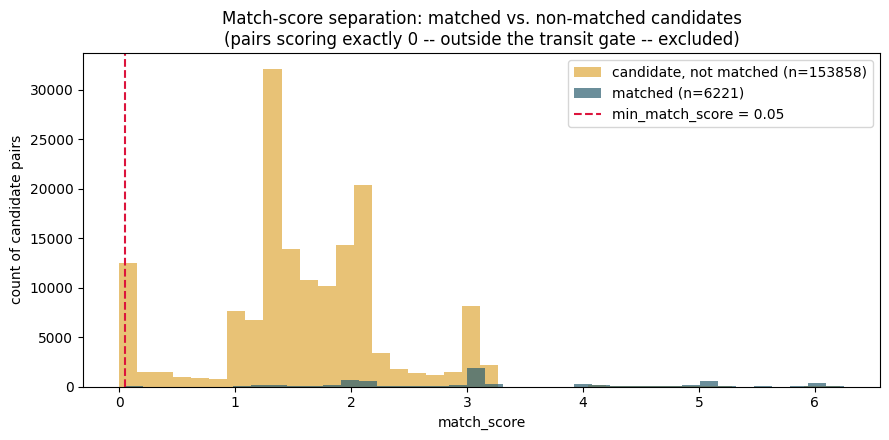

Candidate pairs gated to exactly 0 (outside the (-60s, 180s] transit window): 5537115


In [38]:
matched_scores = []
other_scores = []
gated_zero_count = 0
for date, (a_anchors, b_anchors) in dual_date_anchors.items():
    if not a_anchors or not b_anchors:
        continue
    score, direction, gap = pairwise_scores(a_anchors, b_anchors, final_params)
    solver_score = np.where(score >= final_params["min_match_score"], score, FORBIDDEN_EDGE_SCORE)
    row_idx, col_idx = linear_sum_assignment(-solver_score)
    chosen = set()
    for i, j in zip(row_idx, col_idx):
        if score[i, j] >= final_params["min_match_score"]:
            chosen.add((i, j))
            matched_scores.append(score[i, j])
    n_a, n_b = score.shape
    for i in range(n_a):
        for j in range(n_b):
            if (i, j) in chosen:
                continue
            s = score[i, j]
            if s <= 0:
                gated_zero_count += 1
            else:
                other_scores.append(s)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(other_scores, bins=40, alpha=0.6, label=f"candidate, not matched (n={len(other_scores)})", color="#d99a1b")
ax.hist(matched_scores, bins=40, alpha=0.7, label=f"matched (n={len(matched_scores)})", color="#2c5f6f")
ax.axvline(final_params["min_match_score"], color="crimson", linestyle="--",
           label=f"min_match_score = {final_params['min_match_score']}")
ax.set_xlabel("match_score")
ax.set_ylabel("count of candidate pairs")
ax.set_title("Match-score separation: matched vs. non-matched candidates\n(pairs scoring exactly 0 -- outside the transit gate -- excluded)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Candidate pairs gated to exactly 0 (outside the "
      f"(-{final_params.get('max_overlap_s', 0.0):.0f}s, {final_params['max_transit_s']:.0f}s] "
      f"transit window): {gated_zero_count}")

### Direction split across all 14 dual-sensor dates

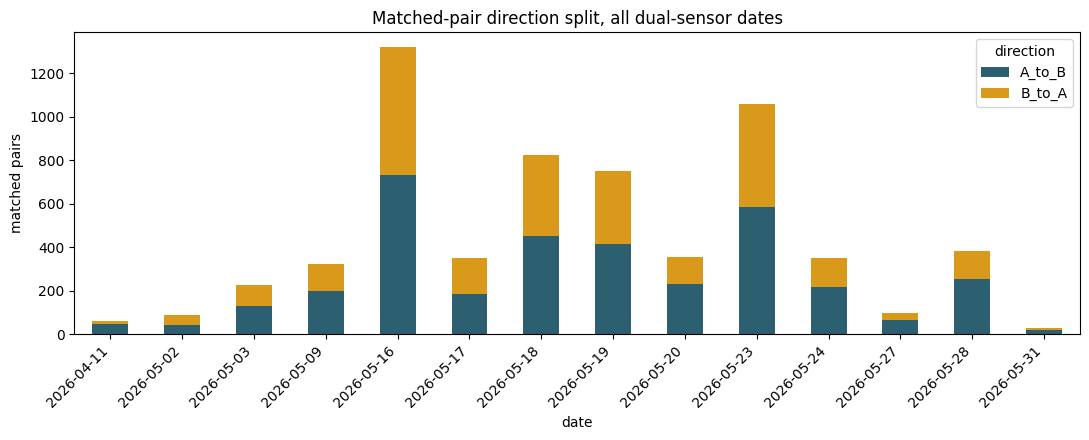

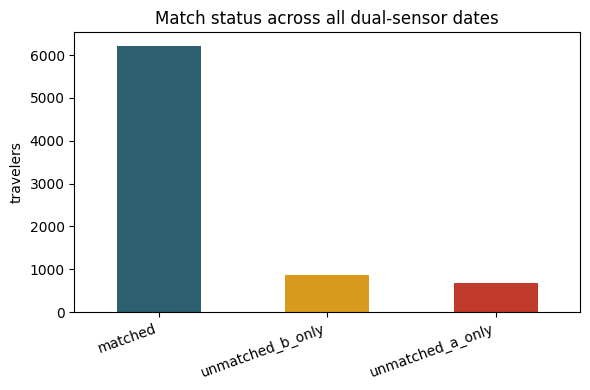

matched             6221
unmatched_b_only     863
unmatched_a_only     669
Name: count, dtype: int64

In [39]:
fig, ax = plt.subplots(figsize=(11, 4.5))
per_date_plot = per_date[[c for c in ("A_to_B", "B_to_A") if c in per_date.columns]]
per_date_plot.plot(kind="bar", stacked=True, ax=ax, color={"A_to_B": "#2c5f6f", "B_to_A": "#d99a1b"})
ax.set_ylabel("matched pairs")
ax.set_title("Matched-pair direction split, all dual-sensor dates")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

status_counts = pd.concat([
    matched_df.assign(match_status="matched")["match_status"],
    unmatched_df["sensor"].map({"A": "unmatched_a_only", "B": "unmatched_b_only"}),
]).value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
status_counts.plot(kind="bar", ax=ax, color=["#2c5f6f", "#d99a1b", "#c0392b"])
ax.set_ylabel("travelers")
ax.set_title("Match status across all dual-sensor dates")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
status_counts

## Validation: spot-check a few matched pairs

In [40]:
sample = matched_df.sort_values("match_score", ascending=False).head(5)
for _, row in sample.iterrows():
    print(f"{row['date']}  {row['traveler_id_a']} <-> {row['traveler_id_b']}  "
          f"direction={row['direction']}  gap={row['transit_gap_s']:.1f}s  score={row['match_score']:.2f}")

2026-05-18  A-158-62 <-> B-243-38  direction=A_to_B  gap=12.0s  score=6.25
2026-05-18  A-171-28 <-> B-254-18  direction=A_to_B  gap=13.0s  score=6.25
2026-05-20  A-242-4 <-> B-324-21  direction=A_to_B  gap=21.0s  score=6.23
2026-05-23  A-256-98 <-> B-408-57  direction=B_to_A  gap=23.0s  score=6.22
2026-05-16  A-101-344 <-> B-188-301  direction=A_to_B  gap=31.0s  score=6.19


## Write output

Design doc §6 requires the output to carry **both** matched pairs and the
travelers only one sensor ever saw, the latter with a null direction.

### Schema of `DATA/travelers_matched_direction.csv` / `.parquet`

| column | matched row | unmatched row |
|---|---|---|
| `date` | collection date | collection date |
| `match_status` | `matched` | `unmatched_a_only` / `unmatched_b_only` |
| `traveler_id_a` | Stage-C Sensor-A `Traveler_ID` | set for `unmatched_a_only`, else NaN |
| `traveler_id_b` | Stage-C Sensor-B `Traveler_ID` | set for `unmatched_b_only`, else NaN |
| `direction` | `A_to_B` or `B_to_A` | **NaN** — no direction is inferable |
| `transit_gap_s` | seconds between the two boundary anchors; in `(-max_overlap_s, max_transit_s]` | NaN |
| `match_score` | see scale below | NaN |

`match_score = transit_time_score + rssi_weight * rssi_shape_score +
order_weight * boundary_order_score + nc_weight * neighborhood_consistency_bonus
+ mac_bonus * same_mac_indicator`, with the first three terms bounded to
[0, 1] and `neighborhood_consistency_bonus` bounded to [0, 1] by
construction; `mac_bonus` is a flat additive constant when a shared MAC
exists. It is a plausibility score, not a probability. `transit_gap_s` can
no longer be absurdly large, and can only be negative within the
calibrated overlap allowance: candidates outside
`(-max_overlap_s, max_transit_s]` score exactly 0 (before the
neighborhood/MAC bonuses, which never apply to a gated-out candidate) and
are rejected. `direction` is assigned by the simple `last_seen`/
`first_seen` rule (see follow-up above), independent of `match_score`.

In [41]:
out_cols = ["date", "match_status", "traveler_id_a", "traveler_id_b",
            "direction", "transit_gap_s", "match_score"]

matched_out = matched_df.copy()
matched_out["match_status"] = "matched"

unmatched_out = unmatched_df.copy()
if len(unmatched_out):
    unmatched_out["match_status"] = unmatched_out["sensor"].map(
        {"A": "unmatched_a_only", "B": "unmatched_b_only"})
    unmatched_out["traveler_id_a"] = unmatched_out["traveler_id"].where(unmatched_out["sensor"] == "A")
    unmatched_out["traveler_id_b"] = unmatched_out["traveler_id"].where(unmatched_out["sensor"] == "B")
    for c in ("direction", "transit_gap_s", "match_score"):
        unmatched_out[c] = np.nan
    unmatched_out = unmatched_out[out_cols]
else:
    unmatched_out = pd.DataFrame(columns=out_cols)

out = pd.concat([matched_out[out_cols], unmatched_out], ignore_index=True)
out = out.sort_values(["date", "match_status"]).reset_index(drop=True)
out.to_csv(f"{DATA_DIR}/travelers_matched_direction.csv", index=False)
out.to_parquet(f"{DATA_DIR}/travelers_matched_direction.parquet", index=False)
print(f"wrote {len(out)} rows to travelers_matched_direction.csv / .parquet")
print(out["match_status"].value_counts().to_string())
print("\ndirection value counts (NaN = unmatched, by construction):")
print(out["direction"].value_counts(dropna=False).to_string())
print("\ntransit_gap_s of matched rows:")
print(out["transit_gap_s"].describe().round(2).to_string())
max_overlap_s = final_params.get("max_overlap_s", 0.0)
print(f"negative transit_gap_s rows: {(out['transit_gap_s'] < 0).sum()} "
      f"(allowed down to -{max_overlap_s:.0f}s; must be 0 if max_overlap_s == 0)")
print(f"transit_gap_s below -{max_overlap_s:.0f}s (would be a bug): "
      f"{(out['transit_gap_s'] < -max_overlap_s).sum()} (must be 0)")

wrote 7753 rows to travelers_matched_direction.csv / .parquet


match_status
matched             6221
unmatched_b_only     863
unmatched_a_only     669

direction value counts (NaN = unmatched, by construction):
direction
A_to_B       3575
B_to_A       2643
NaN          1532
ambiguous       3

transit_gap_s of matched rows:
count    6221.00
mean       22.36
std        47.11
min       -60.00
25%         1.00
50%        14.00
75%        35.00
max       180.00
negative transit_gap_s rows: 1315 (allowed down to -60s; must be 0 if max_overlap_s == 0)
transit_gap_s below -60s (would be a bug): 0 (must be 0)


## Summary & limitations

**Direction detection still does not work well enough to trust for
per-person claims, even after three follow-up fixes across two
revisions.** Tested so far, cheapest first:

1. **Loss fix**: dropped the redundant `total` term from `calibration_loss`
   (it had weighted volumetric error 3x more than directional error).
2. **Transit-gate sweep**: `max_transit_s` is now fitted from
   `{60, 90, 120, 180, 300}`s instead of fixed at 300s.
3. **Boundary order signal** (this revision): first-first/last-last
   ordering agreement across both sensors, plus a bounded overlap
   allowance on the hard transit gate -- see below.

**Result: honestly mixed, not a breakthrough.** `max_transit_s` fitted to
180s -- an *interior* grid value, not a boundary hit like the other four
parameters, so this one genuinely has a preferred setting rather than
saturating. Mean |A→B share error| improved modestly (0.292 → 0.273
against an unchanged 0.369 coin-flip baseline), but correlation between
predicted and manual share across the 8 GT dates got slightly *worse*
(0.533 → 0.490) -- a reminder that both numbers are noisy at n=8 and
neither fix should be read as a clear verdict. The final matched-pair
output applied to all 14 dual-sensor dates is **functionally unchanged**:
identical 5,964 matches, identical 3,179/2,785 direction split, identical
`transit_gap_s` distribution (max 156s) -- because no accepted match ever
needed a gap beyond 156s in the first place, so shrinking the hard gate
from 300s to 180s removed only already-near-zero-scoring candidates, not
real matches. `rssi_weight` still calibrates to 0.0 overall (one
individual leave-one-out fold, holding out 2026-05-19, did find
`rssi_weight=0.5` useful when fit on the other 7 dates -- the "RSSI adds
nothing" conclusion is the dominant pattern, not a universal one).

**Why the fixes didn't break through:** the underlying bottleneck is
unchanged. On busy dates there are many equally-plausible candidate pairs
within the transit-time gate (e.g. ~20 per traveler on the busiest date),
so `(anchor timestamp, rssi_trend)` cannot distinguish the true partner
from an arbitrary one nearby in time. Reweighting the loss or narrowing
the gate changes *which* candidates are admissible, but not the
underlying ambiguity in *which* admissible candidate is correct -- that
requires either a stronger feature (e.g. exploiting a no-overtaking /
single-file-trail assumption, if physically true, to enforce order
preservation between departure and arrival sequences) or more identifying
signal per traveler than `(timestamp, rssi_trend)` provides.

**Third follow-up, this revision: a first-first/last-last "boundary
order" signal -- raised in report review.** The transit gap is keyed on
one specific anchor pair (departure sensor's *last* reading, arrival
sensor's *first* reading), which only gives a positive gap if the two
sensors' coverage is disjoint. Where coverage overlaps, a genuine
traveler can still be seen by the departure sensor *after* the arrival
sensor already picked them up, and the old hard gate rejected that pair
outright regardless of RSSI evidence. `boundary_order_score` checks
first-seen and last-seen order across both sensors independently and
requires both to agree with the candidate direction; `max_overlap_s`
loosens the hard gate to let a bounded amount of negative gap through.

**Result: another modest, real improvement -- same "honestly mixed"
pattern, not a breakthrough.** Held out on the same 8 GT dates: mean
held-out loss improved 1288.9 -> **1137.8** (-12%), mean |A->B share
error| improved 0.273 -> **0.263** (against an unchanged 0.369 coin-flip
baseline), and volumetric accuracy was essentially unchanged
(MAE(total) 18.1 -> 18.0). The fitted `(order_weight, max_overlap_s) =
(0.25, 60s)` is a genuine interior optimum, not a truncated grid edge --
confirmed by re-checking with `order_weight` up to 8 and `max_overlap_s`
up to 180s, same answer both times. Mechanically, the improvement is
**not** mostly "rescuing overlap-zone pairs that were previously
rejected": only 1-4 matched pairs per date actually have a negative
`transit_gap_s`. Most of the change is the order term acting as a
**general tie-breaker** among the many already-valid, similarly-timed
candidates -- the same ambiguity problem diagnosed above, chipped at
slightly rather than solved. Adopted into production (this notebook's
matched-pair output and the CSV/parquet export both use it) since it
strictly improves both honest held-out metrics at no cost to volume, and
is backward compatible (`order_weight = 0` reproduces the old behaviour
exactly).

**Two of the eight GT dates are structurally unreachable, for two
different reasons** (diagnosed this revision, not fixed -- see rationale
below):

- **2026-05-19**: fixable *in principle*. Raw material was sufficient
  (306 raw Sensor-A MACs, far more than the 138 people needed), but Stage
  C's entity resolution compressed them to just 124 travelers at a 59-61%
  compression rate -- well above the 20-53% seen on every other GT
  date -- consistent with the already-documented "people walking together
  get merged" limitation, unusually severe during this specific 76-minute
  peak-traffic window.
- **2026-05-31**: **not fixable by any Stage D or Stage C change**. Even
  the raw MAC count before any clustering (40 on Sensor B) is already
  below the manual total of 56 -- people were never detected in the first
  place, a Stage A/B raw-sensing ceiling (or a fundamental limit of
  BLE-based counting: not everyone carries a BLE-advertising device).

**Decision: Stage C is left unmodified.** Retuning its clustering
threshold could recover some of the 2026-05-19 gap, but validating that
change only against these same 8 Stage-D ground-truth windows risks
overfitting Stage C to Stage D's calibration set, and any change would
touch all 30 collection days' already-reported counts, not just this one
date. Both findings are documented as limitations rather than patched.

**What this means for consumers of `travelers_matched_direction.csv`:**
matched-pair volume and the presence/absence of a match are usable; the
`direction` column should not be used for per-person direction claims,
and only cautiously for aggregate skew.

**Remaining next steps, in priority order:**
1. Test whether a no-overtaking / single-file-trail assumption holds
   physically, and if so, add order-preservation as a **hard constraint**
   on the bipartite matching, not just a soft scoring term. The boundary
   order signal tested this revision is a soft, weighted version of this
   same idea and only moved the needle modestly -- a hard constraint (or
   a joint per-window ordering assignment instead of pairwise scoring)
   is the fundamentally stronger version of it, still untested.
2. Consider a richer pairwise classifier with more features, now that the
   cheaper loss/gate/order fixes are each shown to help only modestly on
   their own.
3. If Stage C's clustering is ever revisited for the 2026-05-19-style
   over-merging pattern, validate against held-out days beyond just these
   8 GT windows to avoid overfitting Stage C to Stage D's calibration set.

## 2026-08-12 update: direction-rule simplification, neighborhood-consistency, same-MAC bonus

Three more follow-up investigations were run since the summary above was
written (full methodology and additional variants tested but not adopted
in `docs/specs/2026-07-30-stage-d-direction-linking-design.md`, follow-up
investigations 4-6). Net result across all three, held out the same way as
everything above:

In [42]:
_final_comparison = pd.DataFrame([
    {"variant": "order signal (2026-08-01 state)", **dict(zip(
        ["MAE(total)", "mean held-out loss", "mean |share error|", "corr"],
        [round(x, 3) for x in summarize(order_loo_report)]))},
    {"variant": "+ neighborhood-consistency", **dict(zip(
        ["MAE(total)", "mean held-out loss", "mean |share error|", "corr"],
        [round(x, 3) for x in summarize(nc_loo_report)]))},
    {"variant": "+ same-MAC bonus (shipped)", **dict(zip(
        ["MAE(total)", "mean held-out loss", "mean |share error|", "corr"],
        [round(x, 3) for x in summarize(mac_loo_report)]))},
])
_final_comparison

,variant,MAE(total),mean held-out loss,mean |share error|,corr
0,order signal (2026-08-01 state),18.000,1137.750,0.263,0.512
1,+ neighborhood-consistency,17.875,997.375,0.240,0.564
2,+ same-MAC bonus (shipped),17.750,945.000,0.213,0.623


**Direction labeling was simplified, not improved** -- follow-up 4 found
`last_seen_A` vs. `last_seen_B` (first-seen as tie-break) reproduces
`direction_candidate_score`'s Gaussian/RSSI/order-based choice on
essentially every matched pair (confirmed above, not assumed). This
notebook now uses that simple rule for the `direction` column; the RSSI
and boundary-order machinery remain exactly as before for deciding *which*
pair wins the assignment, since that is where they were shown to actually
do work.

**Matching itself did improve**, twice, on genuinely new information:

1. **Neighborhood-consistency** (follow-up 5): a bounded per-pair bonus for
   how well a traveler's nearest temporal neighbors' own best candidates
   agree in relative order -- a soft, local alternative to the hard
   no-overtaking constraint tested and rejected earlier (it cost more
   matched volume than it bought back in accuracy). Unlike every other new
   scoring term tried across this project's history, its calibrated weight
   was chosen identically by every leave-one-date-out fold above, not just
   by overfitting to one unstable training split -- the first term in this
   notebook's history with that property.
2. **Same-MAC cross-sensor bonus** (follow-up 6): only ~4% of matched pairs
   share a raw MAC address (MAC randomization defeats it for the rest), but
   that subset is measurably cleaner -- more often mutual-best, faster and
   more physically plausible transit times -- and a small bonus for it
   improves the metrics further at negligible volume cost. Verified this is
   not circular: Stage C's clustering never uses raw MAC identity or
   cross-sensor information (see the follow-up section above), so this is
   genuinely new evidence, not something already implicitly baked into the
   upstream traveler resolution.

**Still not solved.** 2026-05-19 and 2026-05-31 remain structurally
unreachable for the reasons diagnosed above (Stage C recall and a Stage A/B
sensing ceiling, respectively) and continue to dominate the mean held-out
loss regardless of matcher improvements -- no Stage D change can fix a
target that Stage C never produced enough travelers to reach. The
`direction` column is meaningfully better calibrated than it was, but
per-person claims still warrant the same caution as before; aggregate
skew is now the more defensible use, and more so than in the 2026-08-01
state.